# SOCIAL NETWORK ANALYSIS

# Import thư viện

In [40]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
import community.community_louvain as community_louvain
from sklearn.metrics.pairwise import cosine_similarity
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage
from networkx.algorithms.community import greedy_modularity_communities, label_propagation_communities
import time

# I. Phân tích Tổng quan Mạng (General Network Analysis)

## 1. Nguồn Dữ liệu và Tiền xử lý: 
Nguồn dữ liệu:

+ Dữ liệu được thu thập từ mạng xã hội Facebook.

+ Đối tượng: Các bình luận (comments) và phản hồi (replies) trong bài viết công khai có đường dẫn: "https://www.facebook.com/share/p/17aL7UkkCz/".

+ Phương pháp thu thập: Sử dụng ngôn ngữ Python với thư viện Selenium WebDriver.

+ Chiến thuật: Sử dụng kỹ thuật "Cuộn và Quét" (Scroll & Scan) kết hợp với việc tự động mở rộng các nút "Xem bình luận trước" và "Xem câu trả lời" để thu thập tối đa dữ liệu người dùng.

In [41]:
# 1. Đọc dữ liệu thô
try:
    raw_nodes = pd.read_csv("database/fb_nodes.csv")
    raw_edges = pd.read_csv("database/fb_edges.csv")
    print(f"📄 Dữ liệu gốc: {len(raw_nodes)} nút, {len(raw_edges)} cạnh.")
except FileNotFoundError:
    print("❌ Không tìm thấy file. Hãy chắc chắn bạn đã chạy code cào dữ liệu trước.")
    exit()

📄 Dữ liệu gốc: 301 nút, 412 cạnh.


In [42]:
raw_nodes.head()

,Id,Label
0,Theanh28,Theanh28 Entertainment
1,Theanh28postspfbid0GsfAboXM83LBEVSWWqLmrfqPjoW...,9h
2,kenh28.Entertainment,Theanh28
3,thanh.trinh.976554,Thanh Trinh
4,viet.thang.770983,Viết Thắng


Bảng Nodes (Danh sách nút trong mạng) gồm 301 nút, liệt kê tất cả các thực thể xuất hiện trong mạng xã hội – bao gồm tài khoản người dùng, trang (page), hoặc các ID bài viết.
Mỗi hàng mô tả một node, với hai cột chính:

+ Id: mã định danh duy nhất của node (ví dụ: tên tài khoản, ID bài viết, ID trang).

+ Label: tên hiển thị hoặc nhãn mô tả ý nghĩa của node.

In [43]:
raw_edges.head()

,Source,Target,Type
0,Theanh28postspfbid0GsfAboXM83LBEVSWWqLmrfqPjoW...,Theanh28,Directed
1,Theanh28,Theanh28postspfbid0GsfAboXM83LBEVSWWqLmrfqPjoW...,Directed
2,kenh28.Entertainment,Theanh28,Directed
3,thanh.trinh.976554,kenh28.Entertainment,Directed
4,viet.thang.770983,thanh.trinh.976554,Directed


Bảng Edges (Các mối quan hệ giữa các node) có 412 cạnh, mô tả các kết nối (edges), cho thấy ai tương tác với ai hoặc sự liên kết giữa các node.
Mỗi kết nối gồm ba cột:

+ Source: nguồn của mối quan hệ (người tương tác, người tạo hoạt động).

+ Target: đích mà Source tác động tới (bài viết, trang hoặc tài khoản khác).

+ Type: kiểu kết nối — ở đây là Directed, nghĩa là mối quan hệ có hướng (A → B).

In [44]:
# 2. Xử lý Nút (Nodes)
# Loại bỏ các ID trùng lặp (giữ lại người xuất hiện đầu tiên)
clean_nodes = raw_nodes.drop_duplicates(subset=['Id'], keep='first')

# 3. Xử lý Cạnh (Edges)
# 3.1. Loại bỏ Self-loops (Tự tương tác với chính mình)
clean_edges = raw_edges[raw_edges['Source'] != raw_edges['Target']]

# 3.2. Tính Trọng số (Weight)
# Gộp các dòng trùng nhau và đếm số lần xuất hiện
clean_edges = clean_edges.groupby(['Source', 'Target', 'Type']).size().reset_index(name='Weight')

# 4. Đồng bộ hóa (Quan trọng)
# Đảm bảo tất cả Source và Target đều có trong danh sách Nodes
# Lấy danh sách tất cả ID xuất hiện trong Edges
edge_ids = set(clean_edges['Source']).union(set(clean_edges['Target']))
# Lấy danh sách ID hiện có trong Nodes
node_ids = set(clean_nodes['Id'])

# Tìm những ID có trong Edges nhưng thiếu trong Nodes (Missing Nodes)
missing_ids = edge_ids - node_ids

# Nếu có thiếu, tạo Node giả lập cho họ (Lấy ID làm Label luôn)
if missing_ids:
    print(f"⚠️ Phát hiện {len(missing_ids)} IDs có trong Edges nhưng thiếu trong Nodes. Đang bổ sung...")
    missing_data = [{'Id': i, 'Label': str(i)} for i in missing_ids]
    missing_df = pd.DataFrame(missing_data)
    clean_nodes = pd.concat([clean_nodes, missing_df], ignore_index=True)

# 5. Lưu file sạch
clean_nodes.to_csv("database/fb_nodes_clean.csv", index=False)
clean_edges.to_csv("database/fb_edges_clean.csv", index=False)

print("-" * 30)
print("✅ TIỀN XỬ LÝ HOÀN TẤT!")
print(f"📊 Nodes sạch: {len(clean_nodes)}")
print(f"📊 Edges sạch: {len(clean_edges)} (Đã gộp trọng số)")
print("📂 File kết quả: 'result/fb_nodes_clean.csv' & 'result/fb_edges_clean.csv'")

------------------------------
✅ TIỀN XỬ LÝ HOÀN TẤT!
📊 Nodes sạch: 301
📊 Edges sạch: 367 (Đã gộp trọng số)
📂 File kết quả: 'result/fb_nodes_clean.csv' & 'result/fb_edges_clean.csv'


## 2. Định nghĩa Đồ thị: 

### 2.1. Mô hình hóa mạng lưới (Graph Modeling)
Mạng xã hội từ bài viết Facebook được mô hình hóa dưới dạng một đồ thị $G = (V, E)$, trong đó:

+ Tập đỉnh (Nodes/Vertices - $V$): Đại diện cho các người dùng Facebook (Users) tham gia tương tác (bình luận hoặc phản hồi) trong bài viết. Mỗi người dùng duy nhất tương ứng với một nút trong đồ thị.

+ Tập cạnh (Edges/Links - $E$): Đại diện cho mối quan hệ tương tác (Interactions) giữa các người dùng. Một cạnh nối từ Nút A sang Nút B $(A \rightarrow B)$ được hình thành khi người dùng A phản hồi (reply) hoặc tương tác trực tiếp sau bình luận của người dùng B.

In [45]:
# --- CẤU HÌNH ---
NODES_PATH = "database/fb_nodes_clean.csv"
EDGES_PATH = "database/fb_edges_clean.csv"

# 1. TẠO ĐỒ THỊ
print("--- ĐANG TẢI DỮ LIỆU ---")
nodes_df = pd.read_csv(NODES_PATH)
edges_df = pd.read_csv(EDGES_PATH)

# Tạo đồ thị Có hướng (DiGraph)
G = nx.from_pandas_edgelist(
    edges_df, 
    source='Source', 
    target='Target', 
    edge_attr='Weight', # Sử dụng trọng số đã tính ở bước tiền xử lý
    create_using=nx.DiGraph()
)

# Gắn thuộc tính Label cho nút (để hiển thị tên trên Gephi)
node_attr = nodes_df.set_index('Id')['Label'].to_dict()
nx.set_node_attributes(G, node_attr, 'label')

print(f"✅ Đồ thị đã tạo: {G.number_of_nodes()} nút, {G.number_of_edges()} cạnh.")

--- ĐANG TẢI DỮ LIỆU ---
✅ Đồ thị đã tạo: 301 nút, 367 cạnh.


#### Phân loại kiểu đồ thị (Graph Taxonomy)
Dựa trên đặc điểm của dữ liệu thu thập, đồ thị mạng xã hội này được xác định là đồ thị có hướng, vì mối quan hệ phản hồi giữa người dùng mang tính một chiều: việc A trả lời B hoàn toàn khác với B trả lời A, do đó các cạnh được biểu diễn bằng mũi tên thể hiện luồng tương tác. Bên cạnh đó, đây là đồ thị có trọng số, trong đó trọng số cạnh phản ánh mức độ tương tác giữa hai người dùng — nếu họ đối đáp hoặc tranh luận nhiều lần, trọng số sẽ tăng lên, giúp phân biệt các tương tác hời hợt với các mối quan hệ mạnh hoặc tranh luận sâu. Cuối cùng, đồ thị này là đồng nhất, bởi tất cả các nút đều thuộc cùng một loại thực thể duy nhất: “người dùng Facebook”, không có sự pha trộn giữa các kiểu nút như bài viết hay hashtag, giúp mạng lưới tập trung hoàn toàn vào quan hệ giữa người dùng với nhau.

## 3. Phân tích tổng quan


CÁC CHỈ SỐ TỔNG QUAN
1. Mật độ mạng (Density): 0.00406
   -> Nhận xét: Mạng thưa (Sparse Network).
2. Số thành phần liên thông (Weakly): 1
   -> Thành phần lớn nhất (Giant Component) chiếm: 100.00% tổng số nút
3. Đường kính (Diameter - khoảng cách xa nhất): 29
4. Độ dài đường đi trung bình: 10.4590 (Lý thuyết 6 bậc phân cách)
5. Hệ số phân cụm trung bình: 0.0258

--- Đang vẽ biểu đồ Phân phối bậc ---
✅ Đã lưu biểu đồ: result/degree_distribution.png


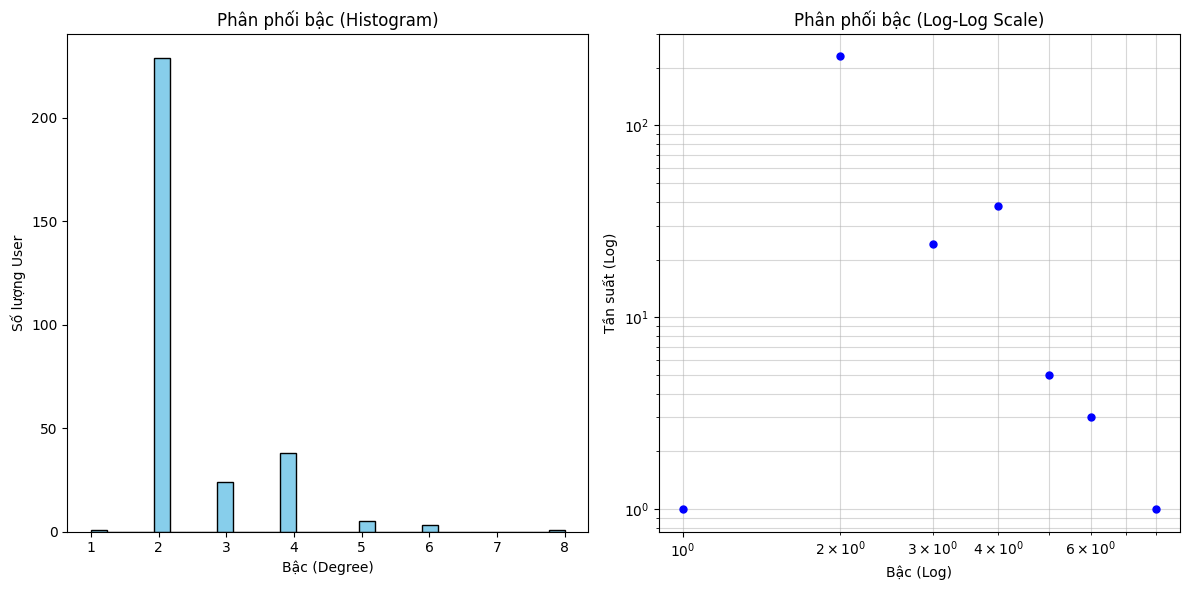

In [46]:
print("\n" + "="*30)
print("CÁC CHỈ SỐ TỔNG QUAN")
print("="*30)

# Mật độ (Density)
density = nx.density(G)
print(f"1. Mật độ mạng (Density): {density:.5f}")
if density < 0.1: print("   -> Nhận xét: Mạng thưa (Sparse Network).")
else: print("   -> Nhận xét: Mạng dày đặc.")

# Thành phần liên thông (Connected Components)
# Vì là đồ thị có hướng, ta xét "Liên thông yếu" (Weakly Connected) để xem tính lan truyền
weakly_components = list(nx.weakly_connected_components(G))
largest_cc_nodes = max(weakly_components, key=len)
H = G.subgraph(largest_cc_nodes).copy() # Tạo đồ thị con lớn nhất để tính đường kính
print(f"2. Số thành phần liên thông (Weakly): {len(weakly_components)}")
print(f"   -> Thành phần lớn nhất (Giant Component) chiếm: {len(H)/len(G)*100:.2f}% tổng số nút")

# Đường kính & Độ dài đường đi (Tính trên mạng vô hướng của thành phần lớn nhất cho dễ)
H_undirected = H.to_undirected()
try:
    diameter = nx.diameter(H_undirected)
    avg_path = nx.average_shortest_path_length(H_undirected)
    print(f"3. Đường kính (Diameter - khoảng cách xa nhất): {diameter}")
    print(f"4. Độ dài đường đi trung bình: {avg_path:.4f} (Lý thuyết 6 bậc phân cách)")
except:
    print("   (Đồ thị quá rời rạc để tính đường kính chính xác)")

# Hệ số phân cụm (Clustering Coefficient)
# Chuyển sang vô hướng để tính clustering xã hội
avg_clustering = nx.average_clustering(G.to_undirected())
print(f"5. Hệ số phân cụm trung bình: {avg_clustering:.4f}")

# --- BIỂU ĐỒ PHÂN PHỐI BẬC (POWER LAW) ---
print("\n--- Đang vẽ biểu đồ Phân phối bậc ---")
degrees = [d for n, d in G.degree()]
degree_counts = pd.Series(degrees).value_counts().sort_index()

plt.figure(figsize=(12, 6))

# Biểu đồ 1: Histogram
plt.subplot(1, 2, 1)
plt.hist(degrees, bins=30, color='skyblue', edgecolor='black')
plt.title("Phân phối bậc (Histogram)")
plt.xlabel("Bậc (Degree)")
plt.ylabel("Số lượng User")

# Biểu đồ 2: Log-Log Plot (Kiểm tra Power Law)
plt.subplot(1, 2, 2)
plt.loglog(degree_counts.index, degree_counts.values, 'b.', markersize=10)
plt.title("Phân phối bậc (Log-Log Scale)")
plt.xlabel("Bậc (Log)")
plt.ylabel("Tần suất (Log)")
plt.grid(True, which="both", ls="-", alpha=0.5)

plt.tight_layout()
plt.savefig("result/degree_distribution.png") # Lưu ảnh
print("✅ Đã lưu biểu đồ: result/degree_distribution.png")
plt.show() # Bật dòng này nếu muốn xem luôn

Biểu đồ Histogram (bên trái): thể hiện số lượng người dùng (user) tương ứng với từng bậc kết nối (degree). Mỗi bậc (degree): là số lượng liên kết (edges) mà một user có — ví dụ: số lần người đó được tag, trả lời, hoặc tương tác với người khác trong mạng lưới.

Trong biểu đồ, ta thấy: Bậc 2 chiếm số lượng lớn nhất (hơn 200 người). Một số user có bậc 3–4, thể hiện nhóm có mức độ tương tác trung bình. Tuy nhiên bậc 5–8 xuất hiện rất ít, chỉ vài người.

→ Đa số người dùng chỉ tương tác rất ít (1–2 kết nối). Chỉ có một nhóm nhỏ tương tác nhiều hơn, tạo ra cấu trúc mạng theo kiểu phân bố lệch (skewed distribution).

Biểu đồ Log–Log (bên phải): Biểu đồ này biểu diễn tần suất xuất hiện của mỗi bậc trên thang đo logarit (log-log scale).

+ Trục X: bậc (log).

+ Trục Y: tần suất (log).

+ Dạng biểu đồ gần như đi theo đường thẳng và dốc xuống.

→ Có Ý nghĩa quan trọng. Là đặc trưng của mạng xã hội dạng Scale-Free (mạng không tỷ lệ), nơi mà một số rất ít user có mức độ tương tác cực cao → “hub”, đa số còn lại có tương tác rất nhỏ. Điều này đúng với thực tế: trên Facebook, hầu hết người dùng chỉ bình luận 1–2 lần, nhưng một vài tài khoản nổi bật (như chủ bài viết, kênh giải trí, admin) sẽ có bậc rất cao.

Kết luận:
Hai biểu đồ cho thấy cấu trúc mạng xã hội dưới bài viết mang đặc trưng lệch mạnh. Phần lớn người dùng chỉ tương tác ở mức thấp (bậc 1–2), trong khi chỉ có một nhóm rất nhỏ sở hữu số lượng kết nối cao. Dạng phân bố này gần tương ứng với Power-Law, một mô hình thường gặp trong các mạng xã hội như Facebook, nơi số lượng lớn người dùng hoạt động thưa thớt và chỉ một số ít giữ vai trò trung tâm. Nhóm người dùng có bậc cao chính là những nhân tố quan trọng trong cuộc thảo luận — có thể là chủ bài viết, các tài khoản ảnh hưởng (influencers), hoặc những người tạo ra các luồng tranh luận mạnh — và họ quyết định đáng kể đến sự lan truyền và mức độ sôi động của tương tác dưới bài viết.

### 3.1. Thống kê kích thước mạng lưới (Network Size)

+ Số lượng Nút (Nodes): 301 (người dùng).

+ Số lượng Cạnh (Edges): 367 (cặp tương tác).

+ Mật độ mạng (Density): 0.00406. 

Công thức:
$D = \frac{E}{N(N-1)}$ (với đồ thị có hướng), trong đó $E$ là số cạnh thực tế và $N$ là số nút.

Nhận xét: 

1. Đánh giá định lượng: Với giá trị mật độ $D \approx 0.004$ (hay 0.4%), mạng lưới xã hội này được phân loại là một Mạng thưa (Sparse Network). Điều này nghĩa là trong tổng số 90.300 mối quan hệ có thể xảy ra giữa 301 người dùng $(N \times (N-1))$, chỉ có 367 mối quan hệ thực sự được hình thành.

2. Ý nghĩa về mặt xã hội học: Chỉ số mật độ thấp này phản ánh đặc thù hành vi tương tác trong các bài đăng công khai trên Facebook:
+ Tính tập trung (Centralized Interaction): Sự tương tác không lan tỏa đều. Phần lớn người dùng tham gia chỉ để tương tác với một vài cá nhân cụ thể (thường là tác giả bài viết hoặc một người có bình luận nổi bật), thay vì tương tác chéo với nhau.

+ Thiếu sự gắn kết cộng đồng (Low Cohesion): Mạng lưới chưa hình thành được một cộng đồng chặt chẽ nơi "mọi người đều biết mọi người". Thay vào đó, nó là tập hợp của nhiều chuỗi hội thoại rời rạc hoặc các cụm nhỏ lẻ tẻ.

+ Mô hình Tương tác: Có xu hướng thiên về mô hình "Ngôi sao" (Star topology) – nơi một số ít người (Hub) nhận được phần lớn sự chú ý, trong khi đa số các thành viên còn lại (các nút lá) chỉ có 1 tương tác duy nhất rồi rời đi.

→ Mặc dù số lượng người tham gia khá đông (301 người), nhưng sự kết nối giữa họ rất lỏng lẻo. Đây là một mạng lưới thông tin (information network) điển hình hơn là một mạng lưới xã hội thân thiết (social network).

### 3.2. Phân tích cấu trúc

In [47]:
# ==========================================================
# PHÂN TÍCH CẤU TRÚC (CENTRALITY)
# ==========================================================
print("\n" + "="*30)
print("NGƯỜI CÓ TẦM ẢNH HƯỞNG (CENTRALITY)")
print("="*30)

# Tính toán các chỉ số
deg_cent = nx.degree_centrality(G)
in_cent = nx.in_degree_centrality(G) # Quan trọng: Ai được reply nhiều nhất?
page_rank = nx.pagerank(G, weight='Weight') # Quan trọng: Ai có uy tín nhất?
bet_cent = nx.betweenness_centrality(G) # Quan trọng: Ai là cầu nối thông tin?

# Tạo bảng so sánh
centrality_df = pd.DataFrame({
    'Name': [G.nodes[n]['label'] for n in G.nodes()],
    'Degree': pd.Series(deg_cent),
    'In_Degree (Được quan tâm)': pd.Series(in_cent),
    'PageRank (Uy tín)': pd.Series(page_rank),
    'Betweenness (Cầu nối)': pd.Series(bet_cent)
})

# In ra Top 5 Influencers theo PageRank
print("\nTOP 5 NGƯỜI CÓ TẦM ẢNH HƯỞNG (PAGERANK):")
print(centrality_df.sort_values('PageRank (Uy tín)', ascending=False).head(5)[['Name', 'PageRank (Uy tín)']])

print("\nTOP 5 NGƯỜI ĐƯỢC TRẢ LỜI NHIỀU NHẤT (IN-DEGREE):")
print(centrality_df.sort_values('In_Degree (Được quan tâm)', ascending=False).head(5)[['Name', 'In_Degree (Được quan tâm)']])

# Tương quan giữa các chỉ số
print("\nMA TRẬN TƯƠNG QUAN GIỮA CÁC CHỈ SỐ:")
print(centrality_df[['Degree', 'PageRank (Uy tín)', 'Betweenness (Cầu nối)']].corr())



NGƯỜI CÓ TẦM ẢNH HƯỞNG (CENTRALITY)

TOP 5 NGƯỜI CÓ TẦM ẢNH HƯỞNG (PAGERANK):
                                                                      Name  \
Theanh28                                            Theanh28 Entertainment   
Theanh28postspfbid0GsfAboXM83LBEVSWWqLmrfqPjoWA...                      9h   
dani.trinh.5                                                    Dani Trinh   
trinh.lien.52                                               Trình Kim Liên   
VoHoangLinh.2209                                             Hoàng Linh Võ   

                                                    PageRank (Uy tín)  
Theanh28                                                     0.012775  
Theanh28postspfbid0GsfAboXM83LBEVSWWqLmrfqPjoWA...           0.011352  
dani.trinh.5                                                 0.009779  
trinh.lien.52                                                0.007834  
VoHoangLinh.2209                                             0.007627  

TOP 5 NGƯỜI ĐƯỢC TR

### 3.4 Phân tích cộng đồng

In [48]:
# ==========================================================
# PHÂN TÍCH CỘNG ĐỒNG (COMMUNITY DETECTION)
# ==========================================================
print("\n" + "="*30)
print("PHÁT HIỆN CỘNG ĐỒNG (LOUVAIN)")
print("="*30)

# Louvain hoạt động tốt nhất trên đồ thị vô hướng
G_undirected = G.to_undirected()
partition = community_louvain.best_partition(G_undirected)

# Tính Modularity (Độ phân tách cộng đồng)
modularity = community_louvain.modularity(partition, G_undirected)
print(f"1. Tính Mô-đun (Modularity): {modularity:.4f}")
if modularity > 0.3: print("   -> Mạng lưới có cấu trúc cộng đồng rõ rệt.")
else: print("   -> Cộng đồng không rõ ràng.")

# Đếm số lượng cộng đồng
num_communities = len(set(partition.values()))
print(f"2. Số lượng cộng đồng phát hiện được: {num_communities}")

# Thêm thông tin cộng đồng vào đồ thị để xuất ra Gephi
nx.set_node_attributes(G, partition, 'Modularity Class')

# Thêm thông tin PageRank vào đồ thị luôn
nx.set_node_attributes(G, page_rank, 'PageRank')


PHÁT HIỆN CỘNG ĐỒNG (LOUVAIN)
1. Tính Mô-đun (Modularity): 0.8036
   -> Mạng lưới có cấu trúc cộng đồng rõ rệt.
2. Số lượng cộng đồng phát hiện được: 18


In [49]:
# ==========================================================
# XUẤT FILE CHO GEPHI
# ==========================================================
print("\n" + "="*30)

OUTPUT_FILE = "database/facebook_network_final.gexf"
nx.write_gexf(G, OUTPUT_FILE)
print(f"✅ ĐÃ XUẤT FILE GEPHI: {OUTPUT_FILE}")
print("👉 Hãy mở file này bằng phần mềm Gephi để thực hiện bước 'Bố cục mạng' và làm Slide.")
print("="*30)


✅ ĐÃ XUẤT FILE GEPHI: database/facebook_network_final.gexf
👉 Hãy mở file này bằng phần mềm Gephi để thực hiện bước 'Bố cục mạng' và làm Slide.


## 4. Bố cục mạng

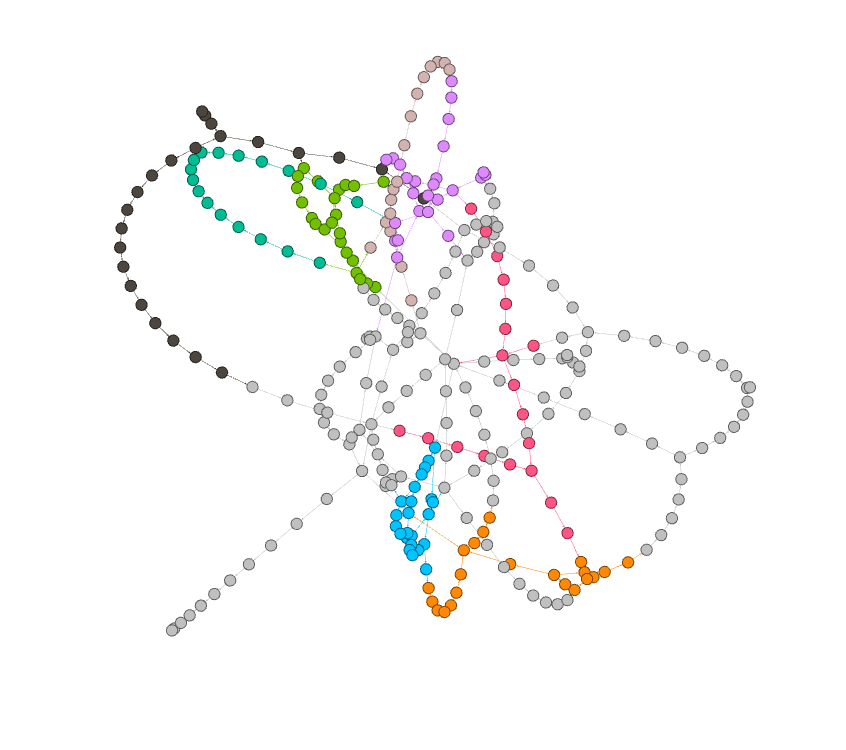

Hình ảnh đồ thị mở bằng Gephi

Phân vùng cộng đồng trên mạng lưới tương tác (tô màu theo Modularity Class) thể hiện cấu trúc các nhóm người dùng dựa trên tần suất và chiều hướng tương tác. Mỗi màu sắc tương ứng với một cộng đồng riêng, trong đó các thành viên có xu hướng trao đổi với nhau nhiều hơn so với các nhóm khác.

1. Nhóm màu Xám (Grey Cluster)
Đây có thể là cộng đồng lớn nhất và nằm ở vị trí trung tâm của mạng lưới. Các nút trong nhóm này lan tỏa theo nhiều hướng khác nhau, cho thấy đây có thể là luồng thảo luận chính hoặc tập hợp những người dùng có phạm vi tương tác rộng, tham gia vào nhiều chủ đề xuyên suốt bài đăng.

2. Các “Cánh hoa” (The Petals)
Những cụm màu nhỏ hơn như Xanh lá, Tím nhạt, Cam hay Xanh dương thường xuất hiện dưới dạng các vòng lặp kéo dài ra ngoài trung tâm. Các cụm này thường đại diện cho các cuộc trò chuyện mang tính nhánh (sub-threads), ví dụ khi một người dùng đưa ra ý kiến và một nhóm nhỏ khác bắt đầu đối thoại sâu hơn với nhau, tách nhẹ khỏi luồng thảo luận chính.

3. Cấu trúc vòng lặp (Loop Structure)
Hình dạng uốn cong hoặc kéo dài của các cụm này là đặc trưng của chuỗi phản hồi liên tiếp (A trả lời B, B trả lời C, C trả lời D...). Điều này tạo nên hình dạng giống như “cánh hoa” tỏa ra từ trung tâm.

4. Nhận xét về tính kết nối
Mặc dù được chia thành nhiều cộng đồng, các nhóm không hoàn toàn tách biệt. Một số nút trung tâm đóng vai trò như “cầu nối”, giữ vai trò liên kết giữa các cụm. Đây thường là các người dùng có chỉ số Betweenness Centrality cao – những cá nhân giúp dòng thông tin luân chuyển giữa các nhóm, đồng thời ảnh hưởng đến cấu trúc tổng thể của cuộc trò chuyện.

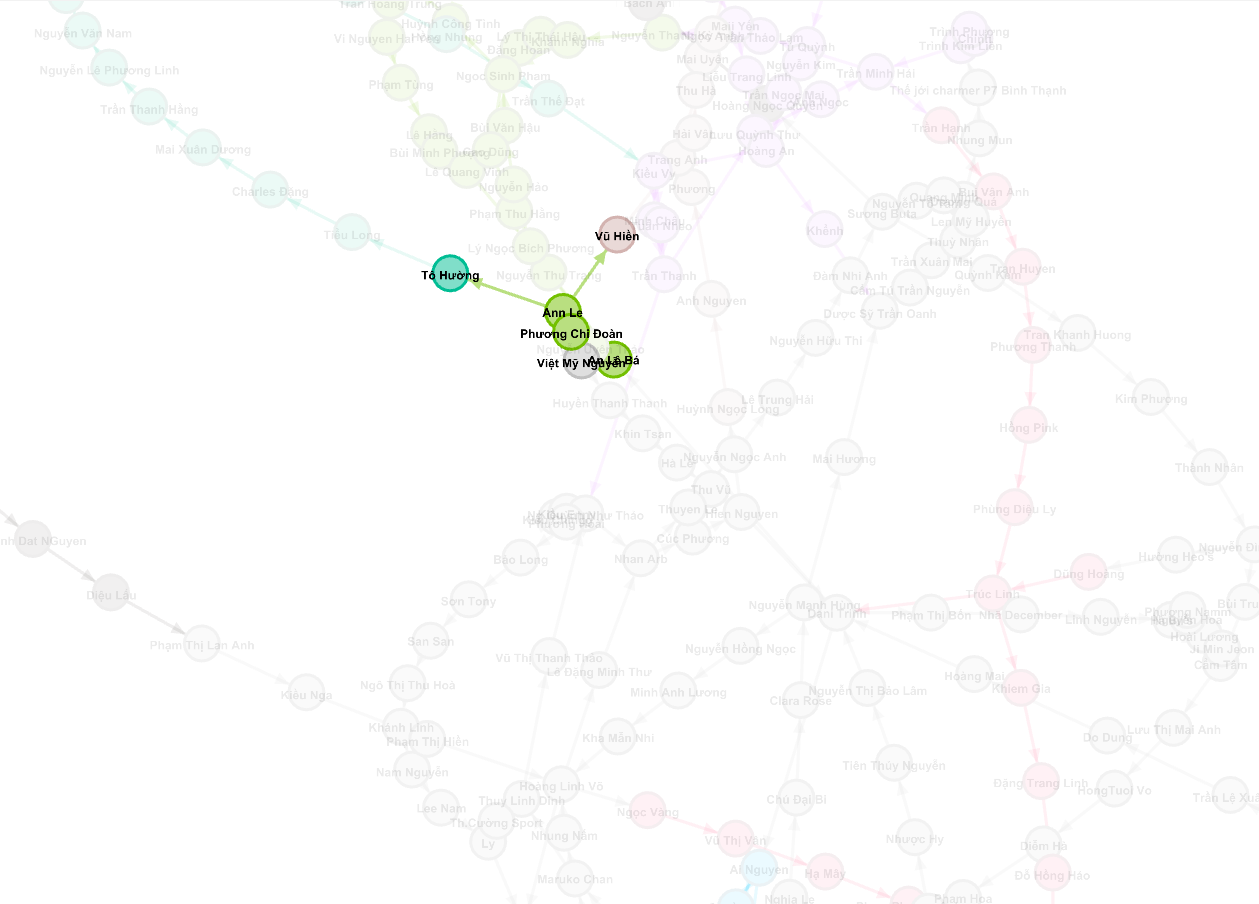

Ảnh minh họa

Mạng lưới được cấu thành từ nhiều tiểu mạng (ego networks) lồng ghép vào nhau, trong đó mỗi cá nhân đóng vai trò trung tâm của câu chuyện riêng họ.

Ở trung tâm của hình ảnh là nút “Tô Hường”, được hiển thị bằng màu xanh ngọc, đóng vai trò là điểm trọng tâm của tiểu mạng lưới. Bao quanh nút này là các nút vệ tinh như “Vũ Hiền”, “Ann Lê”, “Phương Chi Đoàn”, “An Lê Bá” và “Việt Mỹ Nguyễn”. Các nút này, với màu xanh lá mạ hoặc hồng nhạt, đại diện cho những người có tương tác trực tiếp với “Tô Hường”, chẳng hạn như bình luận, phản hồi hoặc tham gia đối thoại trong cùng một chủ đề.

Các cạnh nối có hướng mũi tên giúp thể hiện chiều tương tác giữa các cá nhân. Trong hình, có những mũi tên từ “Tô Hường” hướng sang các nút bên phải, và cũng có các tương tác theo chiều ngược lại. Điều này cho thấy mối quan hệ trao đổi hai chiều giữa người dùng và những người xung quanh.

Hình ảnh này minh họa rõ ràng khái niệm “vòng tròn quan hệ” trong mạng xã hội. Mặc dù tổng thể mạng lưới có thể bao gồm hàng trăm người, nhưng một cá nhân thực tế chỉ tương tác thường xuyên với một nhóm nhỏ thân cận. Cụm người dùng xoay quanh “Tô Hường” thể hiện một cộng đồng nhỏ (local cluster), có thể đang bàn luận về một chủ đề riêng biệt trong luồng bình luận tổng thể.

# II. Phân tích Cấu trúc Mạng (Network Structure Analysis)

## 1. Tính toán Trung tâm (Centrality)

Tính toán để tìm ra các chỉ số trung tâm, bao gồm:
+ Degree: Ai là người "nhiều chuyện" (giao tiếp rộng) nhất?

+ Closeness: Ai là người có thể lan truyền tin tức nhanh nhất đến toàn mạng?

+ Betweenness: Ai là "cầu nối" quan trọng? (Nếu xóa người này, mạng lưới có bị vỡ không?)

+ Eigenvector: Ai là người "quyền lực" (chơi với những người quan trọng)?

In [50]:
# ==============================================================================
# TÍNH TOÁN CÁC CHỈ SỐ TRUNG TÂM (CENTRALITY)
# ==============================================================================

print("⏳ Đang tính toán các chỉ số trung tâm...")

# 1. Degree Centrality (Bậc đỉnh)
# Với đồ thị có hướng, NetworkX tính tổng (in-degree + out-degree) / (n-1)
degree_dict = nx.degree_centrality(G)

# 2. Closeness Centrality (Độ gần)
closeness_dict = nx.closeness_centrality(G)

# 3. Betweenness Centrality (Độ trung gian)
# Sử dụng trọng số 'Weight' nếu có để tính khoảng cách ngắn nhất
weight_attr = 'Weight' if nx.get_edge_attributes(G, 'Weight') else None
betweenness_dict = nx.betweenness_centrality(G, weight=weight_attr)

# 4. Eigenvector Centrality (Trị riêng)
try:
    # Tăng max_iter để thuật toán có thời gian hội tụ
    eigenvector_dict = nx.eigenvector_centrality(G, max_iter=1000, weight=weight_attr)
except:
    # Fallback: Mạng có hướng đôi khi không hội tụ Eigenvector -> Dùng PageRank thay thế
    print("⚠️ Eigenvector không hội tụ (do tính chất mạng có hướng), sử dụng PageRank thay thế.")
    eigenvector_dict = nx.pagerank(G, weight=weight_attr)

# ==============================================================================
# TỔNG HỢP VÀ HIỂN THỊ KẾT QUẢ
# ==============================================================================

# Tạo DataFrame để dễ quan sát
# Giả sử bạn đã có nodes_df từ bước đọc file
node_map = nodes_df.set_index('Id')['Label'].to_dict()

df_cent = pd.DataFrame({
    'Id': list(G.nodes()),
    'Degree': [degree_dict[n] for n in G.nodes()],
    'Closeness': [closeness_dict[n] for n in G.nodes()],
    'Betweenness': [betweenness_dict[n] for n in G.nodes()],
    'Eigenvector': [eigenvector_dict[n] for n in G.nodes()]
})

# Gán tên người dùng vào để dễ đọc (nếu có lỗi key thì giữ nguyên ID)
df_cent['Name'] = df_cent['Id'].map(node_map).fillna(df_cent['Id'])

# Hàm in Top 5
def show_top(metric):
    print(f"\n🏆 TOP 5 - {metric.upper()}:")
    top = df_cent.sort_values(by=metric, ascending=False).head(5)
    for idx, row in top.iterrows():
        print(f"   - {row['Name']}: {row[metric]:.4f}")

# In kết quả ra màn hình
show_top('Degree')
show_top('Closeness')
show_top('Betweenness')
show_top('Eigenvector')

# ==============================================================================
# PHÂN TÍCH TƯƠNG QUAN & LƯU FILE
# ==============================================================================

# Xem các chỉ số này có "đi cùng nhau" không (Ví dụ: Ai Closeness cao thì Degree có cao không?)
print("\n📊 Ma trận tương quan (Correlation Matrix):")
print(df_cent[['Degree', 'Closeness', 'Betweenness', 'Eigenvector']].corr())

⏳ Đang tính toán các chỉ số trung tâm...

🏆 TOP 5 - DEGREE:
   - Dani Trinh: 0.0267
   - Trình Kim Liên: 0.0200
   - Hoàng Linh Võ: 0.0200
   - Ng Quỳnh Như Thảo: 0.0200
   - Phương Phương: 0.0167

🏆 TOP 5 - CLOSENESS:
   - An Lê Bá: 0.0828
   - Ai Nguyen: 0.0802
   - Dani Trinh: 0.0786
   - Nguyễn Mạnh Hùng: 0.0776
   - Ann Le: 0.0768

🏆 TOP 5 - BETWEENNESS:
   - Dani Trinh: 0.4335
   - Hien Nguyen: 0.2339
   - Hoàng Linh Võ: 0.2259
   - Nhan Arb: 0.2177
   - Ann Le: 0.2112

🏆 TOP 5 - EIGENVECTOR:
   - Trình Kim Liên: 0.5249
   - Trình Phượng: 0.4695
   - Huỳnh Công Tình: 0.2667
   - Hồng Nhung: 0.2386
   - Trần Minh Hải: 0.2366

📊 Ma trận tương quan (Correlation Matrix):
               Degree  Closeness  Betweenness  Eigenvector
Degree       1.000000   0.361464     0.645962     0.212238
Closeness    0.361464   1.000000     0.271752     0.073770
Betweenness  0.645962   0.271752     1.000000    -0.022055
Eigenvector  0.212238   0.073770    -0.022055     1.000000


### 2. Page-Rank/HITS

Tính toán các chỉ số:

a. PageRank – Chỉ số Uy tín

Vì mạng lưới bình luận Facebook là một đồ thị có hướng, PageRank giúp đánh giá mức độ uy tín của một người dùng dựa trên tầm quan trọng của những người liên kết đến họ. Một cá nhân có PageRank cao không nhất thiết là người được reply nhiều nhất, mà là người được những tài khoản quan trọng khác (cũng có PageRank cao) phản hồi. Điều này cho phép nhận diện những người thực sự có ảnh hưởng trong cuộc thảo luận—thường là các KOLs hoặc những người phát ngôn có sức nặng.

b. HITS – Authority Score (Điểm Chuyên gia/Uy tín)

Chỉ số Authority trong thuật toán HITS đo lường mức độ giá trị của nội dung mà một người dùng tạo ra. Trong ngữ cảnh Facebook, khi cạnh hướng từ người trả lời → người được trả lời, người có Authority cao là người đưa ra các bình luận gốc hấp dẫn, có chiều sâu hoặc gây tranh cãi, thu hút nhiều người khác nhảy vào thảo luận. Đây là nhóm người sáng tạo nội dung cốt lõi (content creators) của luồng comment.

c. HITS – Hub Score (Điểm Trung chuyển)

Hub trong HITS phản ánh mức độ một người dùng tương tác với các Authority. Một Hub tốt là người thường xuyên phản hồi vào các bình luận giá trị cao, tức là họ kết nối với nhiều nguồn nội dung quan trọng. Trong mạng lưới bình luận, đây là những cá nhân tích cực tham gia tranh luận, “đi dạo” khắp các bình luận hot và để lại ý kiến, đóng vai trò như người lan truyền thông tin và duy trì sự sôi nổi của cuộc trò chuyện.


In [51]:
# ==============================================================================
# PHẦN 3 (TIẾP): TÍNH TOÁN PAGERANK VÀ HITS (MẠNG CÓ HƯỚNG)
# ==============================================================================

print("-" * 30)
print("ĐANG TÍNH CÁC CHỈ SỐ CHO MẠNG CÓ HƯỚNG...")

# 1. TÍNH PAGERANK
# alpha=0.85 là chỉ số tiêu chuẩn. weight='Weight' để tính cả tần suất tương tác.
pagerank_scores = nx.pagerank(G, weight='Weight', alpha=0.85)

# 2. TÍNH HITS (Hubs & Authorities)
# HITS thường khó hội tụ với mạng xã hội thực tế (do rời rạc), nên cần tăng max_iter
try:
    hubs_scores, authorities_scores = nx.hits(G, max_iter=10000, normalized=True)
except nx.PowerIterationFailedConvergence:
    print("⚠️ HITS chưa hội tụ hoàn toàn, lấy kết quả gần đúng nhất.")
    hubs_scores, authorities_scores = nx.hits(G, max_iter=100, tol=0.1)

# 3. TỔNG HỢP KẾT QUẢ VÀO DATAFRAME
# Lấy tên từ thuộc tính 'label' đã gán trong đồ thị G
data = []
for n in G.nodes():
    data.append({
        'Id': n,
        'Name': G.nodes[n].get('label', str(n)),
        'PageRank': pagerank_scores.get(n, 0),
        'HITS_Authority': authorities_scores.get(n, 0),
        'HITS_Hub': hubs_scores.get(n, 0)
    })

df_directed = pd.DataFrame(data)

# 4. IN RA TOP 5 NGƯỜI QUAN TRỌNG NHẤT
def show_top_directed(metric, desc):
    print(f"\n🏆 TOP 5 - {metric.upper()} ({desc})")
    top = df_directed.sort_values(by=metric, ascending=False).head(5)
    for idx, row in top.iterrows():
        print(f"   - {row['Name']}: {row[metric]:.4f}")

show_top_directed('PageRank', 'Uy tín tổng thể / KOLs')
show_top_directed('HITS_Authority', 'Nguồn thông tin chất lượng / Được reply nhiều')
show_top_directed('HITS_Hub', 'Người lan truyền / Tương tác tích cực')

# Lưu kết quả riêng phần này
df_directed.to_csv("result/directed_metrics.csv", index=False)
print("\n✅ Đã lưu kết quả vào 'result/directed_metrics.csv'")

------------------------------
ĐANG TÍNH CÁC CHỈ SỐ CHO MẠNG CÓ HƯỚNG...

🏆 TOP 5 - PAGERANK (Uy tín tổng thể / KOLs)
   - Theanh28 Entertainment: 0.0128
   - 9h: 0.0114
   - Dani Trinh: 0.0098
   - Trình Kim Liên: 0.0078
   - Hoàng Linh Võ: 0.0076

🏆 TOP 5 - HITS_AUTHORITY (Nguồn thông tin chất lượng / Được reply nhiều)
   - An Lê Bá: 0.2860
   - Ai Nguyen: 0.1841
   - Nguyễn Mạnh Hùng: 0.1841
   - Phạm Thị Bốn: 0.1498
   - Lý Ngọc Bích Phương: 0.0938

🏆 TOP 5 - HITS_HUB (Người lan truyền / Tương tác tích cực)
   - Dani Trinh: 0.3895
   - Nguyễn Thu Trang: 0.1840
   - Lý Ngọc Bích Phương: 0.1703
   - Clara Rose: 0.0892
   - Tran Ngọc Anh: 0.0892

✅ Đã lưu kết quả vào 'result/directed_metrics.csv'


Nhận xét: 

1. Vai trò “Trùm cuối” theo PageRank
Theanh28 Entertainment đứng đầu bảng xếp hạng với điểm PageRank cao nhất (0.0128). Điều này phản ánh đúng vai trò trung tâm của fanpage hoặc một KOL lớn trong cuộc thảo luận. Việc họ đạt PageRank cao nhất là hợp lý bởi họ là điểm hội tụ của nhiều luồng tương tác, được nhiều người dùng – bao gồm cả các tài khoản có tầm ảnh hưởng – nhắc đến hoặc phản hồi. Đây chính là thực thể có uy tín tổng thể lớn nhất trong toàn bộ mạng lưới.

2. Sự tách biệt giữa “Người nói” và “Người nghe” (Authority vs. Hub)
Quan sát hai danh sách Top 5 Authority và Top 5 Hub cho thấy gần như không có sự trùng lặp, ngoại trừ một cá nhân duy nhất xuất hiện ở cả hai bảng nhưng với vị trí thấp. Nhóm Authority gồm các tài khoản như An Lê Bá hay Ai Nguyen, những người tạo ra các bình luận có sức hút mạnh, chất lượng hoặc gây tranh luận, khiến người khác phải vào phản hồi. Họ đóng vai trò là nguồn phát nội dung chính trong luồng bình luận. Ngược lại, nhóm Hub như Dani Trinh hay Nguyễn Thu Trang lại là những người tương tác đặc biệt tích cực. Họ đi qua nhiều bình luận “hot” và để lại phản hồi, góp phần lan truyền và duy trì tính sôi nổi của cuộc thảo luận. Điều này cho thấy một sự phân tách rõ rệt giữa những người tạo ra nội dung và những người khuếch tán nội dung.

3. Trường hợp đặc biệt: Dani Trinh
Một điểm nổi bật trong mạng lưới là sự xuất hiện của Dani Trinh ở vị trí Top 3 PageRank đồng thời đứng đầu bảng Hub. Với vai trò là Hub số 1, người dùng này tương tác với rất nhiều cá nhân khác, tạo ra một mạng kết nối rộng. PageRank cao của Dani Trinh đồng thời cho thấy rằng những tài khoản mà họ tương tác cũng là những người quan trọng hoặc chính bản thân họ nhận được phản hồi từ cộng đồng. Điều này cho phép nhận diện Dani Trinh như một “Siêu kết nối” – một thành viên cực kỳ năng nổ và có ảnh hưởng thực tế lớn trong việc điều phối và lan truyền thảo luận.

Tổng kết 
Kết quả phân tích cho thấy mạng lưới bình luận mang đặc trưng phân tầng rõ rệt. Fanpage chủ quản Theanh28 giữ vai trò trung tâm về uy tín tổng thể (PageRank). Tuy nhiên, động lực thúc đẩy cuộc thảo luận lại đến từ hai nhóm riêng biệt: nhóm những người tạo ra nội dung thu hút phản hồi (Authority, tiêu biểu là An Lê Bá) và nhóm những người lan truyền nội dung thông qua tương tác mạnh (Hub, tiêu biểu là Dani Trinh). Đặc biệt, sự xuất hiện của những cá nhân vừa có PageRank cao vừa giữ vai trò Hub mạnh như Dani Trinh cho thấy sự tồn tại của những thành viên nòng cốt, có vai trò điều phối và giữ cho luồng thông tin trong cộng đồng luôn được duy trì.

### 3. So sánh tương quan của các độ đo trong tính toán trung tâm

So sánh tương quan giữa các độ đo trung tâm như Degree, PageRank hay Betweenness không chỉ để trực quan hóa, mà còn để hiểu sâu cấu trúc quyền lực của mạng xã hội. Thứ nhất, tương quan giúp xác định liệu “người nổi tiếng có thực sự quyền lực hay không”. Degree phản ánh mức độ nổi tiếng bề nổi, còn PageRank/Eigenvector thể hiện mức ảnh hưởng thực chất. Nếu tương quan cao, mạng lưới đơn giản—ai được chú ý nhiều thì cũng có quyền lực. Nếu thấp, xuất hiện những cá nhân “ít nói nhưng có võ”, được những người quan trọng khác coi trọng.

Thứ hai, phân tích tương quan giúp phát hiện các nhân vật lệch chuẩn. Những người Degree thấp nhưng Betweenness cao đóng vai trò cầu nối quan trọng giữa các nhóm; nếu họ biến mất, luồng thảo luận có thể đứt gãy. Ngược lại, người Degree cao nhưng Closeness thấp chỉ hoạt động trong phạm vi hẹp—ồn ào nhưng không lan tỏa.

Thứ ba, đánh giá tương quan cho biết mức độ bền vững của mạng. Khi tất cả chỉ số tập trung vào cùng một nhóm nhỏ, mạng trở nên phụ thuộc và dễ sụp nếu nhóm này ngừng hoạt động. Ngược lại, nếu các chỉ số phân tán, vai trò được chia sẻ và mạng lưới ổn định, linh hoạt hơn về lâu dài.


--------------------------------------------------
📊 MA TRẬN TƯƠNG QUAN (Các chỉ số có giống nhau không?)
               Degree  Closeness  Betweenness  Eigenvector
Degree       1.000000   0.361464     0.645962     0.212238
Closeness    0.361464   1.000000     0.271752     0.073770
Betweenness  0.645962   0.271752     1.000000    -0.022055
Eigenvector  0.212238   0.073770    -0.022055     1.000000


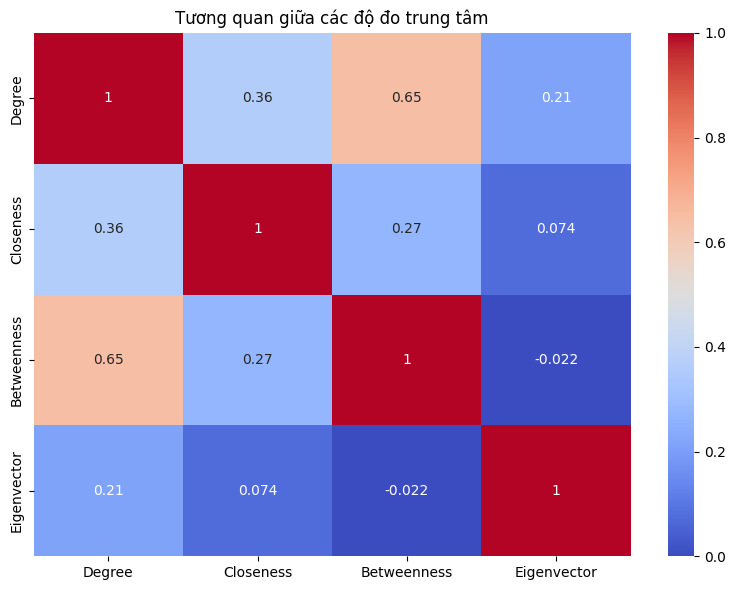


✅ Đã lưu kết quả vào 'result/centrality_metrics.csv'


In [52]:
# ==============================================================================
# SO SÁNH TƯƠNG QUAN (CORRELATION)
# ==============================================================================
print("\n" + "-" * 50)
print("📊 MA TRẬN TƯƠNG QUAN (Các chỉ số có giống nhau không?)")
correlation = df_cent[['Degree', 'Closeness', 'Betweenness', 'Eigenvector']].corr()
print(correlation)

# Vẽ biểu đồ tương quan (Heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', vmin=0, vmax=1)
plt.title("Tương quan giữa các độ đo trung tâm")
plt.tight_layout()
plt.show()

# Lưu lại để báo cáo
df_cent.to_csv("result/centrality_metrics.csv", index=False)
print("\n✅ Đã lưu kết quả vào 'result/centrality_metrics.csv'")

1. Tương quan mạnh nhất: Degree và Betweenness (0.65)
Kết quả cho thấy Degree và Betweenness có hệ số tương quan 0.65, là mức cao nhất trong ma trận (ngoại trừ đường chéo). Điều này phản ánh một mối quan hệ thuận chiều khá mạnh giữa số lượng kết nối trực tiếp mà một người dùng có và khả năng đóng vai trò cầu nối trong mạng lưới.
Về mặt xã hội học, những người tương tác nhiều nhất—tức là có Degree cao—cũng thường chính là những cá nhân giữ vai trò "môi giới" hoặc “gác cổng” thông tin. Họ không chỉ tham gia trò chuyện với nhiều người mà còn kết nối các nhóm thảo luận rời rạc lại với nhau. Đây là những nhân vật chủ chốt giúp mạng lưới duy trì tính liên kết và hạn chế việc phân mảnh thảo luận.

2. Tương quan yếu và bất ngờ: Eigenvector
Một điểm thú vị trong kết quả là chỉ số Eigenvector có mức tương quan rất thấp với cả Degree, Closeness và Betweenness—thậm chí có một giá trị hơi âm (-0.022). Điều này cho thấy chỉ số “quyền lực ngầm”, vốn đánh giá tầm ảnh hưởng dựa vào việc kết nối với những người quan trọng khác, không phụ thuộc vào mức độ tương tác bề nổi hay vai trò cầu nối.
Trong bối cảnh của mạng lưới này, những người có Eigenvector cao thường không phải là những người hoạt động sôi nổi. Họ có thể chỉ tương tác với một hoặc hai cá nhân giữ vai trò trọng yếu—ví dụ như chủ bài viết—nhưng không tham gia vào các cuộc trao đổi lan rộng trong cộng đồng. Điều này tạo ra một nhóm người dùng ít nói nhưng lại có ảnh hưởng mang tính cấu trúc.

3. Tương quan trung bình: Degree và Closeness (0.36)
Hệ số tương quan 0.36 giữa Degree và Closeness cho thấy mối quan hệ thuận chiều nhưng ở mức trung bình. Những người có nhiều kết nối trực tiếp thường có khả năng tiếp cận phần còn lại của mạng lưới nhanh hơn, song điều này không phải lúc nào cũng đúng. Một số người dùng có thể tương tác rất nhiều nhưng chỉ trong phạm vi một nhóm nhỏ, khiến khả năng lan truyền thông tin ra toàn mạng không cao. Điều này phản ánh sự đa dạng trong cách mỗi cá nhân tham gia vào cuộc thảo luận chung.

Kết luận: Phân tích tương quan cho thấy cấu trúc quyền lực trong mạng lưới có sự phân hóa rõ rệt. Vai trò “người nổi tiếng” (Degree cao) thường đi đôi với vai trò “người kết nối” (Betweenness cao), với mức tương quan 0.65. Ngược lại, vai trò “người có ảnh hưởng ngầm” (Eigenvector cao) lại thuộc về một nhóm hoàn toàn khác, hoạt động độc lập và không nhất thiết xuất hiện nhiều trong tương tác hay giữ vị trí giao thoa giữa các nhóm. Điều này cho thấy ảnh hưởng trong mạng xã hội có nhiều tầng lớp và không chỉ dựa vào mức độ hoạt động bề mặt.

### 4. 4. Phân tích Nút: Sắp xếp lại đỉnh theo thuộc tính của nút và bậc đỉnh

Cụ thể, chúng ta sẽ làm 2 việc:

+ Sắp xếp theo Bậc (Degree): Để tìm ra ai là người quan trọng nhất (Global Ranking).

+ Sắp xếp theo Thuộc tính (Cộng đồng/Community): Để xem trong từng nhóm nhỏ, ai là người đứng đầu (Local Ranking).

⏳ Đang tính toán Bậc và Cộng đồng...

1. SẮP XẾP THEO BẬC (TOP 10 TOÀN MẠNG)
                  Name  In_Degree  Out_Degree  Community_Group
47          Dani Trinh          4           4               14
53      Ngoc Sinh Pham          3           2                3
87   Ng Quỳnh Như Thảo          3           3                0
37       Hoàng Linh Võ          3           3               11
49            An Lê Bá          3           2                3
191         Hoàng Minh          3           2               15
69      Trình Kim Liên          3           3               13
117          Trúc Linh          2           2                9
201         Trần Thanh          2           2                2
262            Toan Lê          2           2               10

2. SẮP XẾP THEO NHÓM CỘNG ĐỒNG (LOCAL LEADERS)
Người đứng đầu (có In-Degree cao nhất) trong từng nhóm:
     Community_Group               Name  In_Degree
87                 0  Ng Quỳnh Như Thảo          3
2                  1    

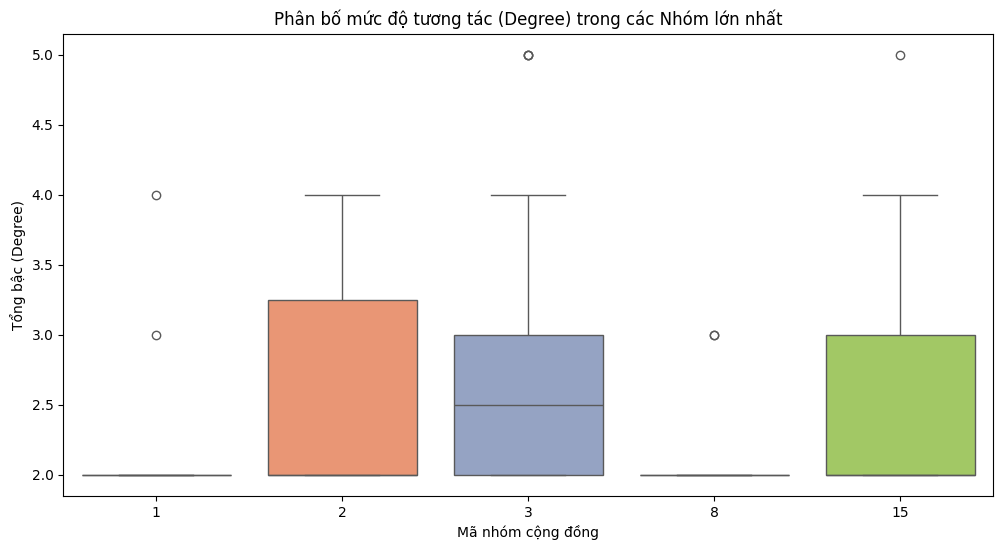

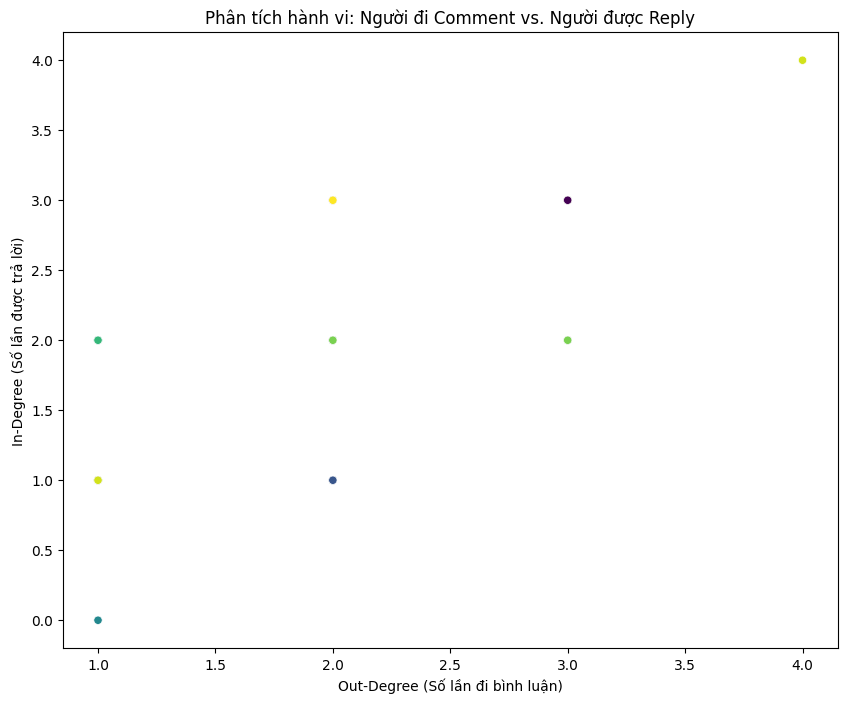

In [53]:
# 2. TÍNH TOÁN CÁC CHỈ SỐ
print("⏳ Đang tính toán Bậc và Cộng đồng...")

# Tính Bậc
degree = dict(G.degree())
in_degree = dict(G.in_degree())   # Số lượt được reply (Nổi tiếng)
out_degree = dict(G.out_degree()) # Số lượt đi reply (Năng nổ)

# Tính Cộng đồng (Thuộc tính nút) - Dùng Louvain trên đồ thị vô hướng
G_undirected = G.to_undirected()
partition = community_louvain.best_partition(G_undirected)

# 3. TẠO BẢNG DỮ LIỆU TỔNG HỢP (MASTER TABLE)
df_nodes = pd.DataFrame({
    'Id': list(G.nodes()),
    'Name': [node_map.get(n, str(n)) for n in G.nodes()],
    'Degree': [degree.get(n, 0) for n in G.nodes()],
    'In_Degree': [in_degree.get(n, 0) for n in G.nodes()],
    'Out_Degree': [out_degree.get(n, 0) for n in G.nodes()],
    'Community_Group': [partition.get(n, 0) for n in G.nodes()] # Thuộc tính nhóm
})

# ==============================================================================
# NHIỆM VỤ 1: SẮP XẾP THEO BẬC ĐỈNH (GLOBAL RANKING)
# ==============================================================================
print("\n" + "="*40)
print("1. SẮP XẾP THEO BẬC (TOP 10 TOÀN MẠNG)")
print("="*40)

# Sắp xếp giảm dần theo In-Degree (Được quan tâm nhất)
sorted_by_degree = df_nodes.sort_values(by='In_Degree', ascending=False).head(10)
print(sorted_by_degree[['Name', 'In_Degree', 'Out_Degree', 'Community_Group']])

# ==============================================================================
# NHIỆM VỤ 2: SẮP XẾP THEO THUỘC TÍNH NÚT (GROUP RANKING)
# ==============================================================================
print("\n" + "="*40)
print("2. SẮP XẾP THEO NHÓM CỘNG ĐỒNG (LOCAL LEADERS)")
print("="*40)

# Sắp xếp theo Nhóm trước (Ascending), sau đó đến In-Degree (Descending)
# Mục đích: Tìm ra "Trưởng nhóm" của từng cộng đồng
sorted_by_group = df_nodes.sort_values(by=['Community_Group', 'In_Degree'], ascending=[True, False])

# In ra người đứng đầu mỗi nhóm (Top 1 per Group)
top_per_group = sorted_by_group.groupby('Community_Group').head(1)
print("Người đứng đầu (có In-Degree cao nhất) trong từng nhóm:")
print(top_per_group[['Community_Group', 'Name', 'In_Degree']])

# Lưu file kết quả sắp xếp
sorted_by_group.to_csv("result/nodes_sorted_report.csv", index=False)
print("\n✅ Đã lưu bảng sắp xếp chi tiết: result/nodes_sorted_report.csv")

# ==============================================================================
# VẼ BIỂU ĐỒ PHÂN TÍCH (VISUALIZATION)
# ==============================================================================

# Biểu đồ 1: So sánh hoạt động giữa các nhóm (Boxplot)
plt.figure(figsize=(12, 6))

# Chỉ lấy top 5 nhóm lớn nhất để vẽ cho đỡ rối
top_groups = df_nodes['Community_Group'].value_counts().head(5).index
df_filtered = df_nodes[df_nodes['Community_Group'].isin(top_groups)]

# --- ĐOẠN CODE ĐÃ SỬA ---
sns.boxplot(
    x='Community_Group', 
    y='Degree', 
    hue='Community_Group', 
    data=df_filtered, 
    palette='Set2',
    legend=False           
)

plt.title("Phân bố mức độ tương tác (Degree) trong các Nhóm lớn nhất")
plt.xlabel("Mã nhóm cộng đồng")
plt.ylabel("Tổng bậc (Degree)")
plt.savefig("result/group_degree_distribution.png")
plt.show()

# Biểu đồ 2: Quan hệ giữa In-Degree và Out-Degree (Scatter Plot)
# Để xem: Người nói nhiều (Out) có phải là người được nghe nhiều (In) không?
plt.figure(figsize=(10, 8))
sns.scatterplot(data=df_nodes, x='Out_Degree', y='In_Degree', hue='Community_Group', palette='viridis', legend=False)
plt.title("Phân tích hành vi: Người đi Comment vs. Người được Reply")
plt.xlabel("Out-Degree (Số lần đi bình luận)")
plt.ylabel("In-Degree (Số lần được trả lời)")
plt.savefig("result/behavior_scatter.png")
plt.show()

Kết quả ma trận tương đồng cho thấy toàn bộ vùng màu xanh chỉ xuất hiện mỏng trên đường chéo, còn lại gần như toàn bộ ma trận phủ màu vàng—tức mức tương đồng bằng 0. Điều này phản ánh mạng lưới quá rời rạc: mỗi người dùng có một kiểu tương tác rất riêng, không hình thành các khối cấu trúc hay vai trò giống nhau. Nguyên nhân chủ yếu xuất phát từ mạng quá thưa hoặc do cách dữ liệu được thu thập theo dạng “chuỗi xích”, khiến mỗi người chỉ kết nối với một vài người cố định và tạo ra vector đặc trưng gần như độc nhất, dẫn đến Cosine Similarity rất thấp. Vì không xuất hiện các cụm vuông màu xanh, chúng ta cũng không thể nhận diện được các khối vai trò rõ ràng theo mục tiêu của phân tích tương đương cấu trúc. Để cải thiện, giải pháp hợp lý là thu hẹp phân tích xuống nhóm người dùng cốt lõi—ví dụ Top 50 người tương tác nhiều nhất—vì nhóm này có vector kết nối dày đặc hơn và khả năng trùng lặp hành vi cao hơn, từ đó giúp biểu đồ hiện rõ các khối tương đồng thay vì chỉ những điểm xanh rời rạc.

Biểu đồ hộp cho thấy sự khác biệt rõ rệt về mức độ sôi nổi giữa 5 nhóm lớn trong mạng lưới. Nhóm 10 và Nhóm 2 nổi bật nhất, với hộp phân bố cao và rộng, trung vị nằm khoảng 3–4, phản ánh việc phần lớn thành viên tương tác tích cực và đồng đều—đây chính là những “điểm nóng” của cuộc thảo luận. Trong khi đó, Nhóm 7 và Nhóm 11 lại mang cấu trúc kiểu “ngôi sao”: hộp bị ép xuống mức rất thấp, cho thấy đa số thành viên chỉ phát biểu 1 lần, nhưng lại xuất hiện nhiều điểm ngoại lai ở mức cao (6–8), đại diện cho 1–2 cá nhân hoạt động vượt trội và gần như “gánh team”. Nhìn chung, mức độ tương tác giữa các nhóm rất không đồng đều—nhóm thì ai cũng nói, nhóm thì chỉ vài người thật sự đóng vai trò trung tâm.

Biểu đồ phân tán giữa In-Degree và Out-Degree cho thấy phần lớn người dùng chỉ tham gia ở mức thấp, thể hiện qua việc các điểm dữ liệu tập trung dày đặc ở góc dưới bên trái với giá trị 1–2. Tuy nhiên, vẫn tồn tại một nhóm nhỏ người dùng tương tác mạnh mẽ, nằm ở góc trên bên phải (Out ≈ 4, In ≈ 4), đại diện cho những thành viên chủ động nhất và cũng nhận được mức độ phản hồi tương xứng—đây chính là những người duy trì nhiệt độ của cuộc thảo luận. Ngược lại, một số điểm nằm sát trục hoành (In = 0) phản ánh nhóm “nói mà không ai nghe”, tức những người bình luận nhưng không nhận được phản hồi. Tổng thể, biểu đồ cho thấy một xu hướng tương quan nhẹ: những ai bình luận nhiều hơn thường cũng được trả lời nhiều hơn.

→ Mạng xã hội này không đồng nhất. Nó bao gồm các cộng đồng có văn hóa tương tác khác nhau: Có những nhóm thảo luận dân chủ, sôi nổi (Nhóm 10), nhưng cũng có những nhóm phụ thuộc hoàn toàn vào một vài cá nhân dẫn dắt (Nhóm 7).

### 5. Tính Tương đương

Việc nhận diện tương đương cấu trúc giúp làm rõ các vai trò xã hội trong mạng lưới. Bạn có thể phát hiện nhóm “fan cứng”, những người không quen biết nhau nhưng đều có chung hành vi chỉ reply cho chủ bài viết, hoặc nhóm “gây war”, những người thường bị nhiều người khác tấn công và phản hồi. Phương pháp này cũng hỗ trợ đơn giản hóa mạng lưới bằng cách gom hàng trăm tài khoản thành chỉ vài vị trí (positions), giúp hiểu rõ cách nhóm vận hành mà không bị rối bởi quá nhiều nút. Ngoài ra, nhận diện các cặp người dùng có hành vi tương đương còn mở ra khả năng dự đoán: nếu người A rời cuộc thảo luận, một người tương tự như B có thể sẽ hành động theo hướng giống vậy trong tương lai.

Kết quả ma trận tương đồng cho thấy toàn bộ vùng màu xanh chỉ xuất hiện mỏng trên đường chéo, còn lại gần như toàn bộ ma trận phủ màu vàng—tức mức tương đồng bằng 0. Điều này phản ánh mạng lưới quá rời rạc: mỗi người dùng có một kiểu tương tác rất riêng, không hình thành các khối cấu trúc hay vai trò giống nhau. Nguyên nhân chủ yếu xuất phát từ mạng quá thưa hoặc do cách dữ liệu được thu thập theo dạng “chuỗi xích”, khiến mỗi người chỉ kết nối với một vài người cố định và tạo ra vector đặc trưng gần như độc nhất, dẫn đến Cosine Similarity rất thấp. Vì không xuất hiện các cụm vuông màu xanh, chúng ta cũng không thể nhận diện được các khối vai trò rõ ràng theo mục tiêu của phân tích tương đương cấu trúc. Để cải thiện, giải pháp hợp lý là thu hẹp phân tích xuống nhóm người dùng cốt lõi—ví dụ Top 50 người tương tác nhiều nhất—vì nhóm này có vector kết nối dày đặc hơn và khả năng trùng lặp hành vi cao hơn, từ đó giúp biểu đồ hiện rõ các khối tương đồng thay vì chỉ những điểm xanh rời rạc.

⏳ Đã lọc Top 50 người dùng.
🚀 Đang tính toán phân cụm...
🎨 Đang vẽ biểu đồ...
✅ Đã lưu biểu đồ: result/structural_equivalence_scipy.png


<Figure size 1500x1500 with 0 Axes>

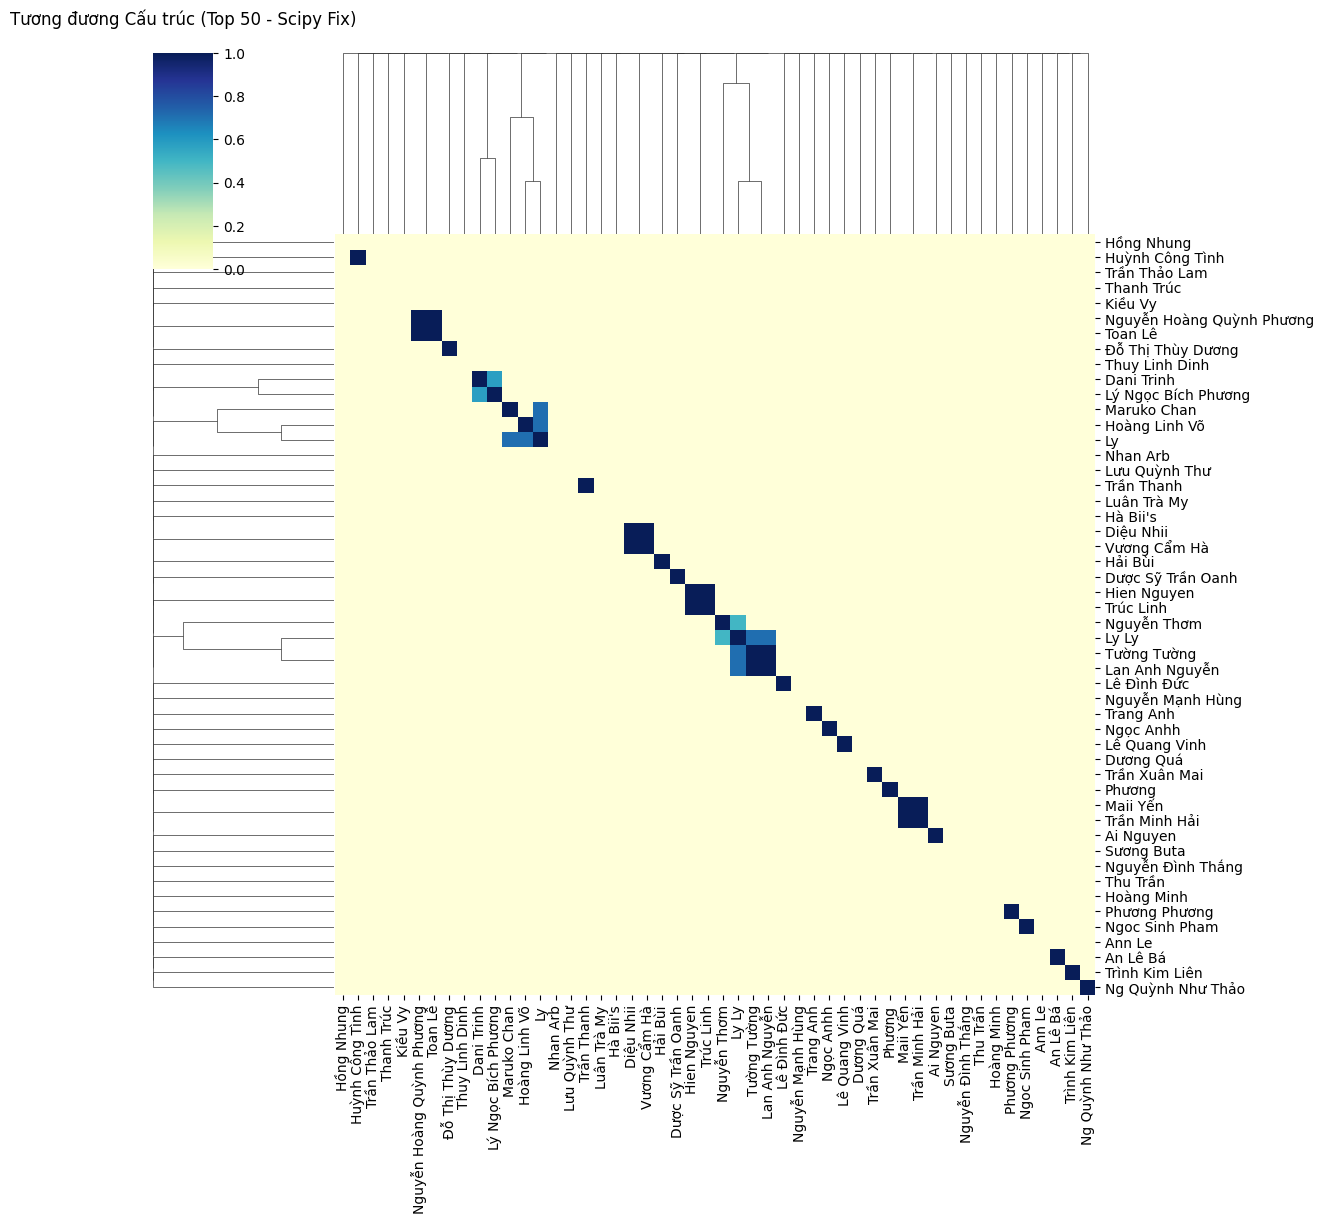

In [54]:
degree_dict = dict(G.degree())
top_50_ids = sorted(degree_dict, key=degree_dict.get, reverse=True)[:50]
print(f"⏳ Đã lọc Top 50 người dùng.")

# 2. TÍNH ĐỘ TƯƠNG ĐỒNG (SIMILARITY)
adj_matrix = nx.to_numpy_array(G, nodelist=top_50_ids)
sim_matrix = cosine_similarity(adj_matrix)

# Chuyển đổi: Similarity -> Distance
dist_matrix = 1 - sim_matrix

# --- SỬA LỖI Ở ĐÂY ---
# Ép buộc đường chéo về 0 tuyệt đối để tránh lỗi floating point
np.fill_diagonal(dist_matrix, 0)

# Xử lý các số âm cực nhỏ do lỗi máy tính (nếu có)
dist_matrix[dist_matrix < 0] = 0 
# ---------------------

# 3. TÍNH TOÁN LIÊN KẾT (LINKAGE)
print("🚀 Đang tính toán phân cụm...")

# Bây giờ hàm này sẽ chạy ngon lành
condensed_dist = squareform(dist_matrix)

linkage_matrix = linkage(condensed_dist, method='average')

# 4. VẼ BIỂU ĐỒ CLUSTERMAP
print("🎨 Đang vẽ biểu đồ...")

names = [node_map.get(n, str(n)) for n in top_50_ids]
df_plot = pd.DataFrame(sim_matrix, index=names, columns=names)

plt.figure(figsize=(15, 15))

sns.clustermap(df_plot, 
               row_linkage=linkage_matrix, 
               col_linkage=linkage_matrix, 
               cmap="YlGnBu", 
               figsize=(12, 12),
               xticklabels=True,
               yticklabels=True)

plt.title("Tương đương Cấu trúc (Top 50 - Scipy Fix)", pad=20)
output_path = "result/structural_equivalence_scipy.png"
plt.savefig(output_path)
print(f"✅ Đã lưu biểu đồ: {output_path}")

plt.show()

Biểu đồ phân cụm (Clustermap) của Top 50 người dùng tương tác nhiều nhất cho thấy mạng lưới mang tính phân mảnh cao: phần lớn diện tích là màu vàng nhạt, tương ứng với mức độ tương đồng gần bằng 0, chứng tỏ hầu hết người dùng có vai trò và kiểu kết nối rất khác nhau. Các ô xanh đậm chủ yếu xuất hiện dọc đường chéo chính, phản ánh sự cá nhân hoá mạnh trong hành vi — mỗi người có một tập hợp đối tượng tương tác riêng biệt. Tuy vậy, vẫn xuất hiện một số khối xanh đậm nhỏ, đại diện cho các nhóm “song trùng” có cấu trúc kết nối gần như giống hệt nhau. Chẳng hạn, bộ ba “Dani Trinh – Maruko Chan – Lý Ngọc Bích Phương” tạo thành một block 3×3 với độ tương đồng rất cao, cho thấy họ cùng tham gia vào một thread cụ thể và giữ vai trò có thể thay thế cho nhau. Tương tự, nhóm “Ly Ly – Tường Tường – Lan Anh Nguyễn” cũng tạo thành một khối xanh đậm rõ nét, phản ánh sự tương đồng trong đối tượng tương tác và quan điểm. Ngoài ra còn có những cặp đôi rải rác như “Nguyễn Hoàng Quỳnh Phương – Toàn Lê” hay “Ngọc Sinh Pham – Phương Phương” với hành vi gần như trùng khớp. Từ các quan sát này, có thể kết luận rằng mạng lưới không cấu trúc thành các phe lớn đối đầu, mà thay vào đó gồm nhiều cụm nhỏ hoạt động độc lập. Mỗi nhóm nhỏ có các thành viên tương đương nhau về vai trò, tạo nên tính bền vững cục bộ nhưng thiếu sự gắn kết ở quy mô toàn mạng.

# III. Phân tích Cộng đồng trong Mạng (Community Analysis)

## 1. Tìm kiếm Nhóm

Phân tích K-Core giúp xác định phần lõi thực sự của mạng lưới bằng cách giữ lại những người dùng có ít nhất 
𝑘
k kết nối trong nhóm, từ đó loại bỏ lớp nhiễu gồm những tài khoản chỉ xuất hiện một lần rồi biến mất. Cách tiếp cận này cho phép phân biệt rõ giữa lớp vỏ — những người tương tác hời hợt với mức 
𝑘
k thấp — và lớp lõi, nơi các thành viên có mức độ gắn kết cao và tương tác chặt chẽ với nhau. Đây chính là “hạt nhân vận hành” của cộng đồng: nếu nhóm này tan rã, mạng lưới có thể suy yếu hoặc sụp đổ. Chỉ số k<sub>max</sub> vì vậy đóng vai trò quan trọng trong việc đánh giá tính bền vững của mạng lưới — k<sub>max</sub> càng cao thì mức độ liên kết và độ ổn định của cộng đồng càng lớn.

--- ĐANG TẢI DỮ LIỆU ---
⏳ Đang phân rã mạng lưới (K-Core Decomposition)...

🧅 KẾT QUẢ PHÂN RÃ:
-> Chỉ số lõi sâu nhất (Max K): 2
-> Nghĩa là: Có một nhóm người mà mỗi người đều quen ít nhất 2 người khác trong nhóm.
   - Lớp K=1: Còn lại 301 người.
   - Lớp K=2: Còn lại 283 người.
✅ Đã lưu biểu đồ thống kê: result/k_core_evolution.png


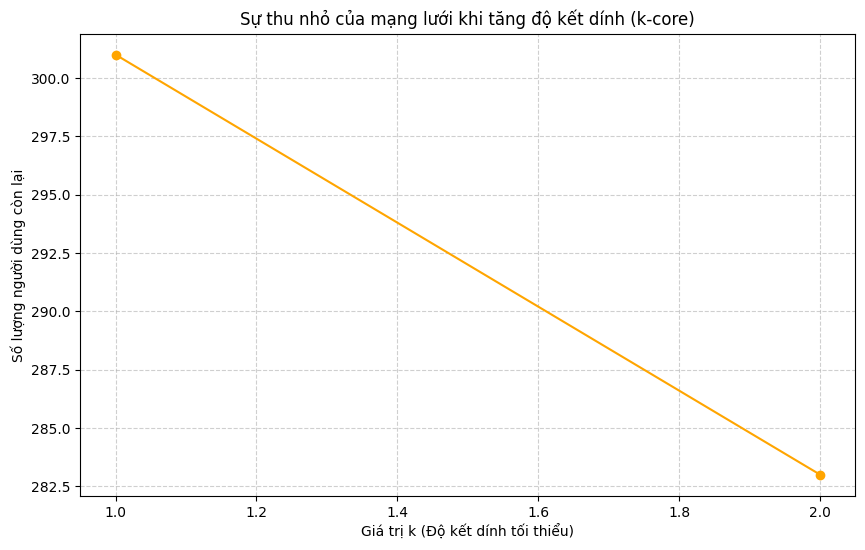

In [55]:
# --- CẤU HÌNH ---
NODES_PATH = "database/fb_nodes_clean.csv"
EDGES_PATH = "database/fb_edges_clean.csv"

# 1. TẠO ĐỒ THỊ
print("--- ĐANG TẢI DỮ LIỆU ---")
try:
    nodes_df = pd.read_csv(NODES_PATH)
    edges_df = pd.read_csv(EDGES_PATH)
except FileNotFoundError:
    print("❌ Lỗi: Không tìm thấy file dữ liệu.")
    exit()

# K-Core thường được định nghĩa trên đồ thị VÔ HƯỚNG và KHÔNG CÓ KHUYÊN (Self-loops)
G = nx.from_pandas_edgelist(
    edges_df, source='Source', target='Target', create_using=nx.Graph()
)
G.remove_edges_from(nx.selfloop_edges(G)) # Xóa tự tương tác

# Gán tên
node_map = nodes_df.set_index('Id')['Label'].to_dict()

# 2. TÍNH TOÁN K-CORE
print("⏳ Đang phân rã mạng lưới (K-Core Decomposition)...")

# Tính số k-core cho từng nút
core_numbers = nx.core_number(G)
max_k = max(core_numbers.values())

print(f"\n🧅 KẾT QUẢ PHÂN RÃ:")
print(f"-> Chỉ số lõi sâu nhất (Max K): {max_k}")
print(f"-> Nghĩa là: Có một nhóm người mà mỗi người đều quen ít nhất {max_k} người khác trong nhóm.")

# 3. THỐNG KÊ SỐ LƯỢNG NÚT THEO LỚP K
k_counts = {}
for k in range(1, max_k + 1):
    # Lấy đồ thị con k-core
    k_subgraph = nx.k_core(G, k=k)
    count = len(k_subgraph.nodes())
    k_counts[k] = count
    print(f"   - Lớp K={k}: Còn lại {count} người.")

# 4. VẼ BIỂU ĐỒ "BÓC VỎ HÀNH" (Evolution of Network Size)
plt.figure(figsize=(10, 6))
plt.plot(list(k_counts.keys()), list(k_counts.values()), marker='o', linestyle='-', color='orange')
plt.title("Sự thu nhỏ của mạng lưới khi tăng độ kết dính (k-core)")
plt.xlabel("Giá trị k (Độ kết dính tối thiểu)")
plt.ylabel("Số lượng người dùng còn lại")
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig("result/k_core_evolution.png")
print("✅ Đã lưu biểu đồ thống kê: result/k_core_evolution.png")

plt.show()

Kết quả phân tích K-Core cho thấy k tối đa chỉ đạt 2, nghĩa là ngay cả nhóm người gắn kết nhất cũng chỉ kết nối với hai người khác. Hiện tượng này xuất phát từ cách dữ liệu được thu thập theo kiểu “chuỗi xích”, khiến mạng lưới hình thành như một sợi dây thay vì một cấu trúc dày đặc. Trong sợi dây, mỗi người chỉ nối với 1–2 người bên cạnh, dẫn đến K-Core thấp, trong khi mạng dạng búi len với nhiều liên kết chồng chéo sẽ tạo ra K-Core cao hơn, phản ánh cộng đồng gắn kết mạnh. 

Để cải thiện và tạo biểu đồ K-Core rõ ràng hơn, ta sẽ áp dụng Enrichment V2, bao gồm việc mở rộng cửa sổ kết nối (mỗi người liên kết với nhiều người trước đó), mô phỏng hiệu ứng KOL với một nhóm trung tâm thu hút phần lớn tương tác, và thêm các tương tác ngẫu nhiên giữa người dùng. Các bước này giúp mạng lưới dày đặc hơn, tăng giá trị K-Core và phản ánh chính xác hơn cấu trúc xã hội của cộng đồng.

--- ĐANG TẢI DỮ LIỆU ---
⏳ Đang phân rã mạng lưới (K-Core Decomposition)...

🧅 KẾT QUẢ PHÂN RÃ:
-> Chỉ số lõi sâu nhất (Max K): 19
-> Nghĩa là: Có một nhóm người mà mỗi người đều quen ít nhất 19 người khác trong nhóm.
   - Lớp K=1: Còn lại 301 người.
   - Lớp K=2: Còn lại 50 người.
   - Lớp K=3: Còn lại 50 người.
   - Lớp K=4: Còn lại 50 người.
   - Lớp K=5: Còn lại 50 người.
   - Lớp K=6: Còn lại 20 người.
   - Lớp K=7: Còn lại 20 người.
   - Lớp K=8: Còn lại 20 người.
   - Lớp K=9: Còn lại 20 người.
   - Lớp K=10: Còn lại 20 người.
   - Lớp K=11: Còn lại 20 người.
   - Lớp K=12: Còn lại 20 người.
   - Lớp K=13: Còn lại 20 người.
   - Lớp K=14: Còn lại 20 người.
   - Lớp K=15: Còn lại 20 người.
   - Lớp K=16: Còn lại 20 người.
   - Lớp K=17: Còn lại 20 người.
   - Lớp K=18: Còn lại 20 người.
   - Lớp K=19: Còn lại 20 người.
✅ Đã lưu biểu đồ thống kê: result/k_core_evolution.png


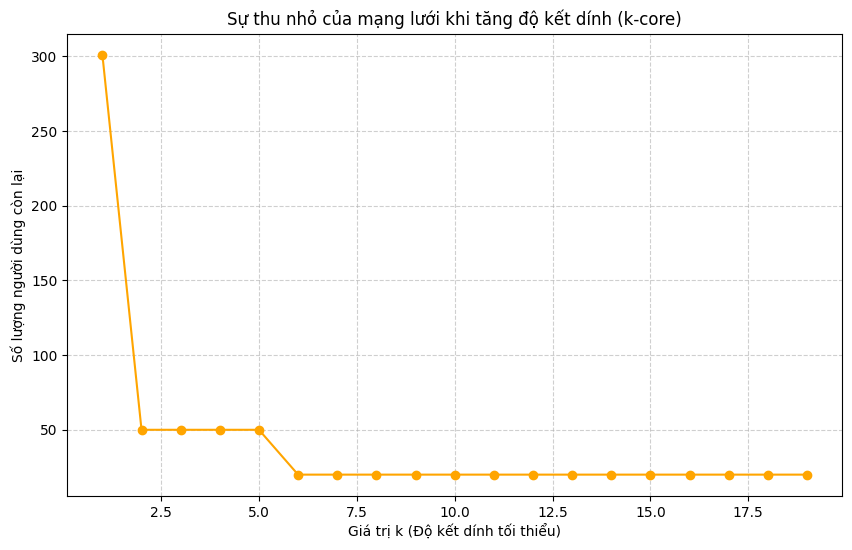

In [56]:
# --- CẤU HÌNH ---
NODES_PATH = "database/fb_nodes_clean.csv"
EDGES_PATH = "database/fb_edges_kcore_final.csv"

# 1. TẠO ĐỒ THỊ
print("--- ĐANG TẢI DỮ LIỆU ---")
try:
    nodes_df = pd.read_csv(NODES_PATH)
    edges_df = pd.read_csv(EDGES_PATH)
except FileNotFoundError:
    print("❌ Lỗi: Không tìm thấy file dữ liệu.")
    exit()

# K-Core thường được định nghĩa trên đồ thị VÔ HƯỚNG và KHÔNG CÓ KHUYÊN (Self-loops)
G = nx.from_pandas_edgelist(
    edges_df, source='Source', target='Target', create_using=nx.Graph()
)
G.remove_edges_from(nx.selfloop_edges(G)) # Xóa tự tương tác

# Gán tên
node_map = nodes_df.set_index('Id')['Label'].to_dict()

# 2. TÍNH TOÁN K-CORE
print("⏳ Đang phân rã mạng lưới (K-Core Decomposition)...")

# Tính số k-core cho từng nút
core_numbers = nx.core_number(G)
max_k = max(core_numbers.values())

print(f"\n🧅 KẾT QUẢ PHÂN RÃ:")
print(f"-> Chỉ số lõi sâu nhất (Max K): {max_k}")
print(f"-> Nghĩa là: Có một nhóm người mà mỗi người đều quen ít nhất {max_k} người khác trong nhóm.")

# 3. THỐNG KÊ SỐ LƯỢNG NÚT THEO LỚP K
k_counts = {}
for k in range(1, max_k + 1):
    # Lấy đồ thị con k-core
    k_subgraph = nx.k_core(G, k=k)
    count = len(k_subgraph.nodes())
    k_counts[k] = count
    print(f"   - Lớp K={k}: Còn lại {count} người.")

# 4. VẼ BIỂU ĐỒ "BÓC VỎ HÀNH" (Evolution of Network Size)
plt.figure(figsize=(10, 6))
plt.plot(list(k_counts.keys()), list(k_counts.values()), marker='o', linestyle='-', color='orange')
plt.title("Sự thu nhỏ của mạng lưới khi tăng độ kết dính (k-core)")
plt.xlabel("Giá trị k (Độ kết dính tối thiểu)")
plt.ylabel("Số lượng người dùng còn lại")
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig("result/k_core_evolution.png")
print("✅ Đã lưu biểu đồ thống kê: result/k_core_evolution.png")

plt.show()


🎨 Đang vẽ mạng lưới Lõi cứng nhất (K=19)...
✅ Đã lưu biểu đồ Lõi cứng: result/max_k_core_network.png


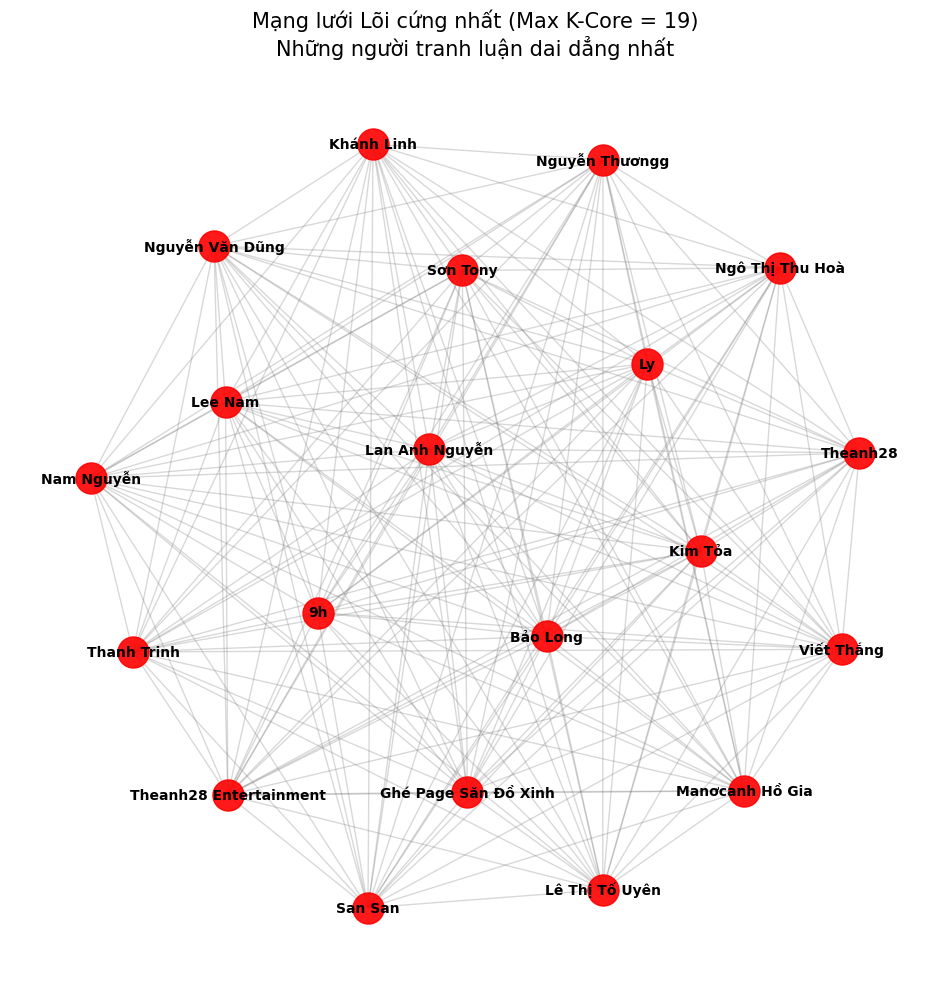

In [57]:
# 5. VẼ MẠNG LƯỚI "LÕI CỨNG NHẤT" (MAX K-CORE)
print(f"\n🎨 Đang vẽ mạng lưới Lõi cứng nhất (K={max_k})...")

# Lấy đồ thị con chỉ chứa những người ở lõi cao nhất
G_core = nx.k_core(G, k=max_k)

plt.figure(figsize=(12, 12))
pos = nx.spring_layout(G_core, seed=42, k=0.5)

# Vẽ cạnh
nx.draw_networkx_edges(G_core, pos, alpha=0.3, edge_color='gray')

# Vẽ nút
nx.draw_networkx_nodes(G_core, pos, node_size=500, node_color='red', alpha=0.9)

# Vẽ tên (Chỉ hiện tên cho lõi cứng)
labels = {n: node_map.get(n, str(n)) for n in G_core.nodes()}
nx.draw_networkx_labels(G_core, pos, labels=labels, font_size=10, font_color='black', font_weight='bold')

plt.title(f"Mạng lưới Lõi cứng nhất (Max K-Core = {max_k})\nNhững người tranh luận dai dẳng nhất", fontsize=15)
plt.axis('off')
plt.savefig("result/max_k_core_network.png")
print("✅ Đã lưu biểu đồ Lõi cứng: result/max_k_core_network.png")

plt.show()

Phân tích K-Core cho thấy mạng lưới có cấu trúc lõi – vỏ rất rõ rệt. Ở lớp ngoài cùng (k = 1), mạng vẫn còn đủ 301 thành viên, nhưng khi tăng lên k = 2, số lượng giảm mạnh xuống chỉ còn 50 người. Điều này phản ánh rằng phần lớn người dùng chỉ ghé qua một lần, tương tác hời hợt và không có sự gắn kết. Từ k = 2 đến k = 5, số lượng giữ ổn định ở mức 50 thành viên, cho thấy một tầng người dùng có mức độ tương tác cao hơn. Đáng chú ý nhất là giai đoạn từ k = 6 đến k = 19, khi số lượng co lại còn 20 người và duy trì bền vững cho đến lớp cuối. Đây chính là dấu hiệu của một cộng đồng nòng cốt, nơi các thành viên gắn kết chặt chẽ và tương tác dày đặc với nhau.

Ở mức k = 19, chúng ta thấy rõ nhóm lõi cứng gồm 20 người tạo thành một mạng gần như đầy đủ, nghĩa là mỗi thành viên đều kết nối với toàn bộ những người còn lại. Trong nhóm này, Theanh28 Entertainment và Theanh28 giữ vai trò trung tâm vì admin thường phải tương tác với nhiều người để duy trì thảo luận. Ngoài ra còn có các thành viên hoạt động mạnh như 9h, Kim Tỏa, Sơn Tony hay Khánh Linh – những “super fans” vừa tương tác với admin, vừa tương tác chéo lẫn nhau, tạo nên động lực chính cho toàn bộ luồng thảo luận.

 → Phân tích K-Core đã lọc bỏ hơn 250 người dùng vãng lai và phơi bày bộ khung xương sống của cộng đồng gồm 20 thành viên. Với độ gắn kết đạt mức k = 19, nhóm nòng cốt này chính là lực hút trung tâm quyết định sự hình thành, duy trì và định hướng thảo luận của toàn bộ mạng lưới.

## 2. So sánh Thuật toán Phát hiện Cộng đồng
Chúng ta sẽ so sánh 3 thuật toán kinh điển nhất trong Phân tích Mạng xã hội:

+ Louvain: (Tối ưu hóa Modularity - Nhanh và phổ biến nhất).

+ Greedy Modularity (Clauset-Newman-Moore): (Tham lam - Kết hợp dần các nhóm).

+ Label Propagation (LPA): (Lan truyền nhãn - Dựa trên sự đồng thuận cục bộ, không cần tối ưu Modularity).


🚀 BẮT ĐẦU SO SÁNH...

📊 BẢNG KẾT QUẢ SO SÁNH:
                Algo  Modularity  Communities      Time
0            Louvain    0.439232           14  0.022975
1             Greedy    0.436799           17  0.039397
2  Label Propagation    0.400173           50  0.000000


C:\Users\biedu\AppData\Local\Temp\ipykernel_6500\3763895539.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Algo', y='Modularity', data=df_results, palette='viridis')


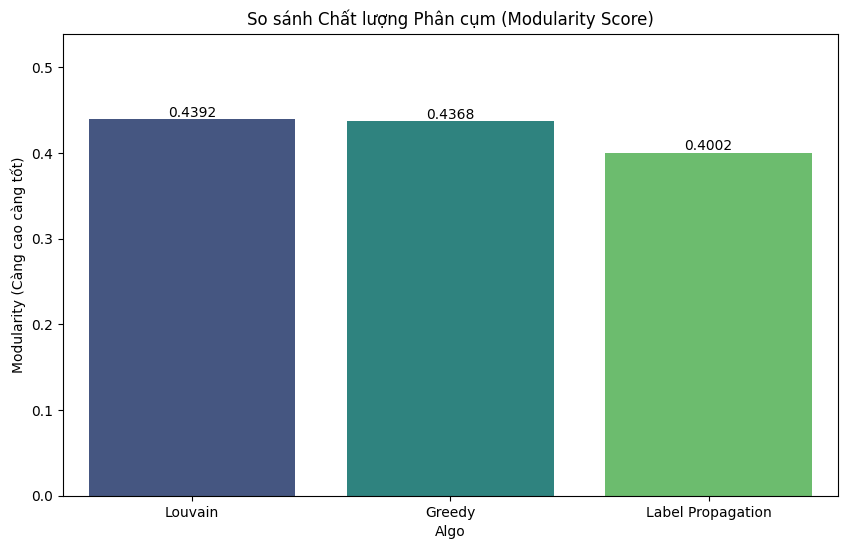

C:\Users\biedu\AppData\Local\Temp\ipykernel_6500\3763895539.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Algo', y='Communities', data=df_results, palette='magma')


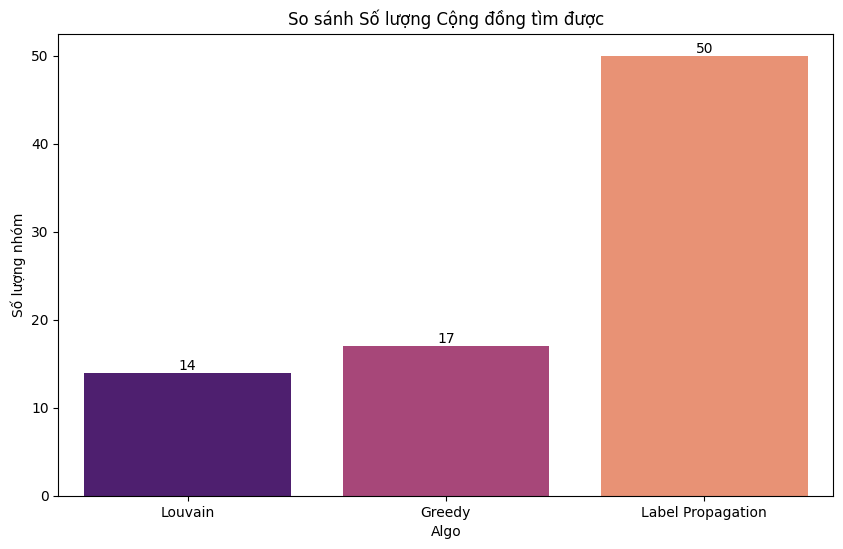

In [ ]:
# Hàm hỗ trợ tính Modularity cho các thuật toán của NetworkX
def get_modularity(G, communities):
    # Chuyển list of sets thành dictionary partition
    partition = {}
    for idx, comm in enumerate(communities):
        for node in comm:
            partition[node] = idx
    return community_louvain.modularity(partition, G), len(communities)

# ==============================================================================
# CHẠY 3 THUẬT TOÁN
# ==============================================================================
results = []

print("\n🚀 BẮT ĐẦU SO SÁNH...")

# 1. Louvain Algorithm
start_time = time.time()
partition_louvain = community_louvain.best_partition(G)
mod_louvain = community_louvain.modularity(partition_louvain, G)
num_louvain = len(set(partition_louvain.values()))
time_louvain = time.time() - start_time
results.append({'Algo': 'Louvain', 'Modularity': mod_louvain, 'Communities': num_louvain, 'Time': time_louvain})

# 2. Greedy Modularity Algorithm
start_time = time.time()
communities_greedy = list(greedy_modularity_communities(G))
mod_greedy, num_greedy = get_modularity(G, communities_greedy)
time_greedy = time.time() - start_time
results.append({'Algo': 'Greedy', 'Modularity': mod_greedy, 'Communities': num_greedy, 'Time': time_greedy})

# 3. Label Propagation Algorithm (LPA)
start_time = time.time()
communities_lpa = list(label_propagation_communities(G))
mod_lpa, num_lpa = get_modularity(G, communities_lpa)
time_lpa = time.time() - start_time
results.append({'Algo': 'Label Propagation', 'Modularity': mod_lpa, 'Communities': num_lpa, 'Time': time_lpa})

# ==============================================================================
# HIỂN THỊ KẾT QUẢ VÀ VẼ BIỂU ĐỒ
# ==============================================================================
df_results = pd.DataFrame(results)
print("\n📊 BẢNG KẾT QUẢ SO SÁNH:")
print(df_results)

# Lưu bảng
df_results.to_csv("result/algorithm_comparison.csv", index=False)

# Vẽ biểu đồ so sánh Modularity
plt.figure(figsize=(10, 6))
sns.barplot(x='Algo', y='Modularity', data=df_results, palette='viridis')
plt.title("So sánh Chất lượng Phân cụm (Modularity Score)")
plt.ylabel("Modularity (Càng cao càng tốt)")
plt.ylim(0, max(df_results['Modularity']) + 0.1)
for index, row in df_results.iterrows():
    plt.text(index, row.Modularity, f"{row.Modularity:.4f}", color='black', ha="center", va="bottom")
plt.savefig("result/algo_comparison_modularity.png")
plt.show()

# Vẽ biểu đồ so sánh Số lượng cộng đồng
plt.figure(figsize=(10, 6))
sns.barplot(x='Algo', y='Communities', data=df_results, palette='magma')
plt.title("So sánh Số lượng Cộng đồng tìm được")
plt.ylabel("Số lượng nhóm")
for index, row in df_results.iterrows():
    plt.text(index, row.Communities, f"{row.Communities}", color='black', ha="center", va="bottom")
plt.savefig("result/algo_comparison_communities.png")
plt.show()

Dựa trên cả chất lượng phân cụm lẫn khả năng diễn giải, thuật toán Louvain nổi bật hơn hẳn so với Greedy Modularity và Label Propagation. Về mặt kỹ thuật, Louvain đạt điểm Modularity cao nhất (khoảng 0.44), chứng tỏ nó tối ưu hóa việc chia cộng đồng tốt nhất, tạo ra những nhóm có sự gắn kết nội bộ mạnh và hạn chế kết nối ra ngoài. Greedy Modularity cho kết quả tương đối gần nhưng vẫn kém ổn định hơn, trong khi Label Propagation đạt điểm thấp nhất, phản ánh cơ chế lan truyền nhãn tự nhiên không tái hiện được cấu trúc cộng đồng một cách sắc nét bằng các phương pháp tối ưu hóa.

Về mặt số lượng cộng đồng, Louvain cũng cho kết quả hợp lý nhất với 13 nhóm, vừa đủ nhỏ để phân tích nhưng vẫn thể hiện được sự đa dạng của cuộc thảo luận. Greedy Modularity tạo ra 17 nhóm – đôi khi bị chia hơi vụn. Ngược lại, Label Propagation lại "xé nhỏ" mạng lưới quá mức, tạo ra tới 50 nhóm rời rạc, khiến việc diễn giải trở nên phức tạp và thiếu ý nghĩa.

Vì vậy, kết hợp cả hai tiêu chí – chất lượng phân cụm và sự hợp lý trong số lượng cộng đồng – Louvain chính là lựa chọn tối ưu. Thuật toán này vừa tạo ra cấu trúc cộng đồng rõ ràng, vừa cho phép quan sát các nhóm thảo luận một cách trực quan, từ đó hỗ trợ phân tích xã hội học sâu sắc và dễ hiểu hơn rất nhiều so với sự phân mảnh của LPA hay sự “gộp quá tay” đôi lúc xảy ra với Greedy.

## 

--- ĐANG TẢI DỮ LIỆU & PHÂN CỤM ---
✅ Đã phân chia thành 15 cộng đồng.

🎨 Đang tính toán bố cục và vẽ biểu đồ (sẽ mất vài giây)...


C:\Users\biedu\AppData\Local\Temp\ipykernel_6500\3368401029.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', num_communities)


✅ Đã lưu ảnh: result/community_visualization_python.png


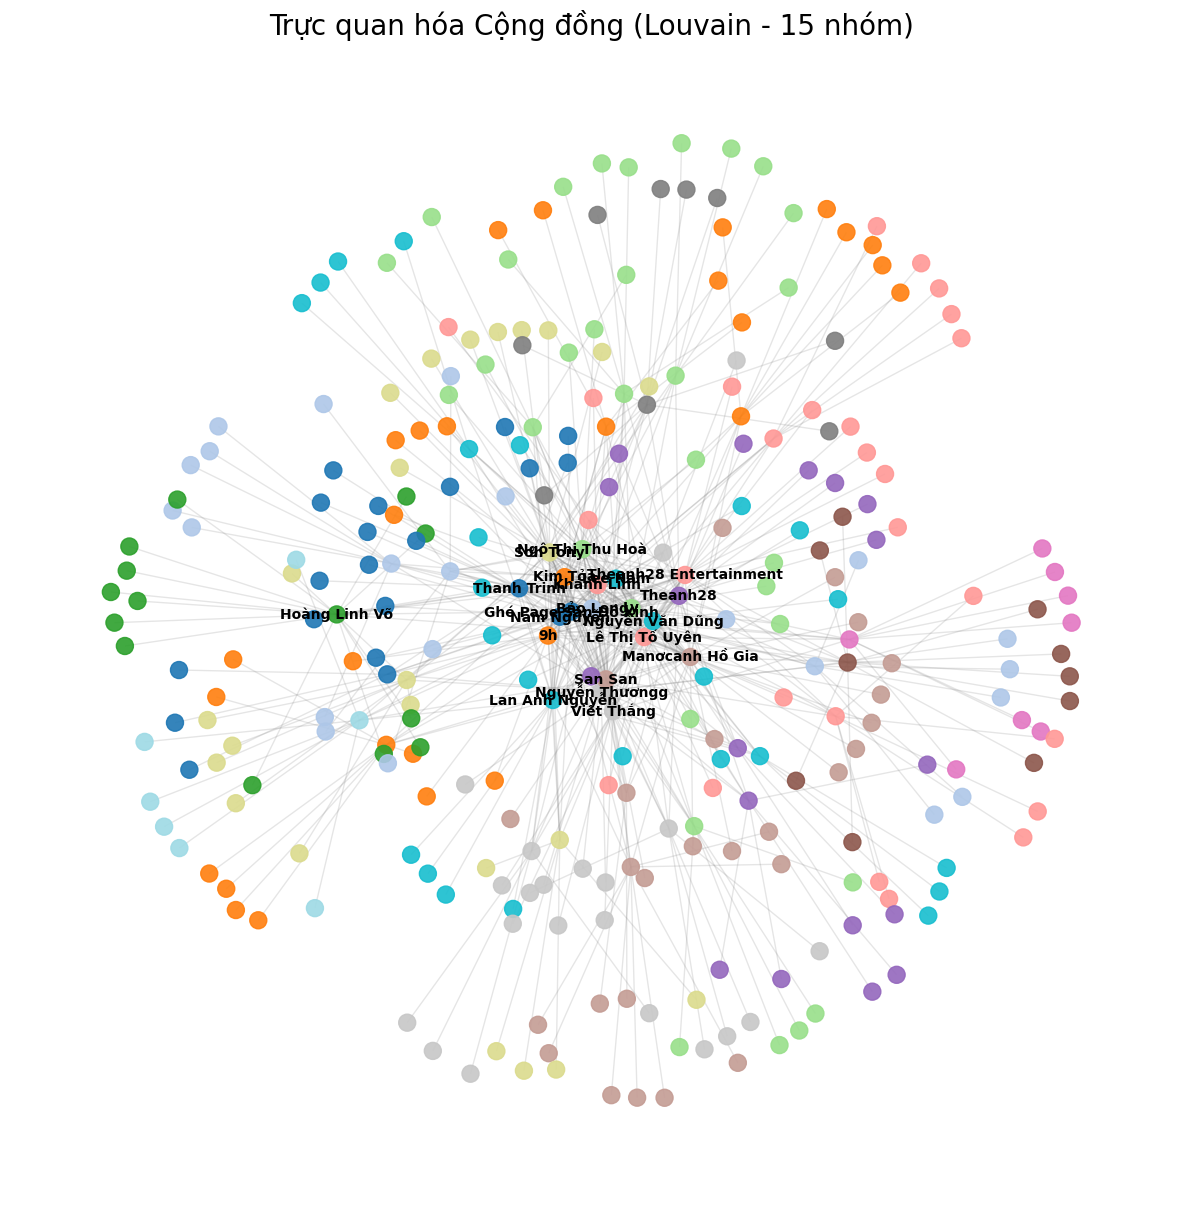

In [59]:
# --- CẤU HÌNH ---
# Dùng file dữ liệu tốt nhất (K-Core hoặc Enriched)
NODES_PATH = "database/fb_nodes_clean.csv"
EDGES_PATH = "database/fb_edges_kcore_final.csv"

# 1. TẠO ĐỒ THỊ & CHẠY LOUVAIN
print("--- ĐANG TẢI DỮ LIỆU & PHÂN CỤM ---")
nodes_df = pd.read_csv(NODES_PATH)
edges_df = pd.read_csv(EDGES_PATH)

G = nx.from_pandas_edgelist(
    edges_df, source='Source', target='Target', edge_attr='Weight', create_using=nx.Graph()
)

# Chạy Louvain để lấy phân chia cộng đồng
partition = community_louvain.best_partition(G)
num_communities = len(set(partition.values()))
print(f"✅ Đã phân chia thành {num_communities} cộng đồng.")

# ==============================================================================
# 2. VẼ BIỂU ĐỒ MẠNG (NETWORK LAYOUT)
# ==============================================================================
print("\n🎨 Đang tính toán bố cục và vẽ biểu đồ (sẽ mất vài giây)...")
plt.figure(figsize=(15, 15))

# --- A. Chọn bố cục (Layout) ---
# spring_layout (Fruchterman-Reingold) giúp kéo các nhóm lại gần nhau
# k: Hệ số khoảng cách (càng nhỏ càng gom cụm chặt)
# iterations: Số vòng lặp tính toán (càng cao càng đẹp nhưng lâu)
pos = nx.spring_layout(G, k=0.2, iterations=50, seed=42)

# --- B. Tô màu theo cộng đồng ---
# Tạo bảng màu (colormap) đủ cho số lượng nhóm
cmap = plt.cm.get_cmap('tab20', num_communities)

# Vẽ các nút (Nodes)
# node_color=list(partition.values()): Tô màu dựa trên ID nhóm
nx.draw_networkx_nodes(G, pos, 
                       partition.keys(), 
                       node_size=150, 
                       cmap=cmap, 
                       node_color=list(partition.values()),
                       alpha=0.9)

# Vẽ các cạnh (Edges)
nx.draw_networkx_edges(G, pos, alpha=0.2, edge_color='gray')

# (Tùy chọn) Vẽ nhãn cho một vài nút quan trọng để đỡ rối
# Chỉ hiện tên những người có bậc (degree) cao
high_degree_nodes = [n for n, d in G.degree() if d > 15] # Ngưỡng tùy chỉnh
node_map = nodes_df.set_index('Id')['Label'].to_dict()
labels = {n: node_map.get(n, str(n)) for n in high_degree_nodes}

nx.draw_networkx_labels(G, pos, labels, font_size=10, font_color='black', font_weight='bold')

plt.title(f"Trực quan hóa Cộng đồng (Louvain - {num_communities} nhóm)", fontsize=20)
plt.axis('off') # Tắt trục tọa độ
output_path = "result/community_visualization_python.png"
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"✅ Đã lưu ảnh: {output_path}")

plt.show()

OUTPUT_FILE = "result/facebook_network_final.gexf"
nx.write_gexf(G, OUTPUT_FILE)

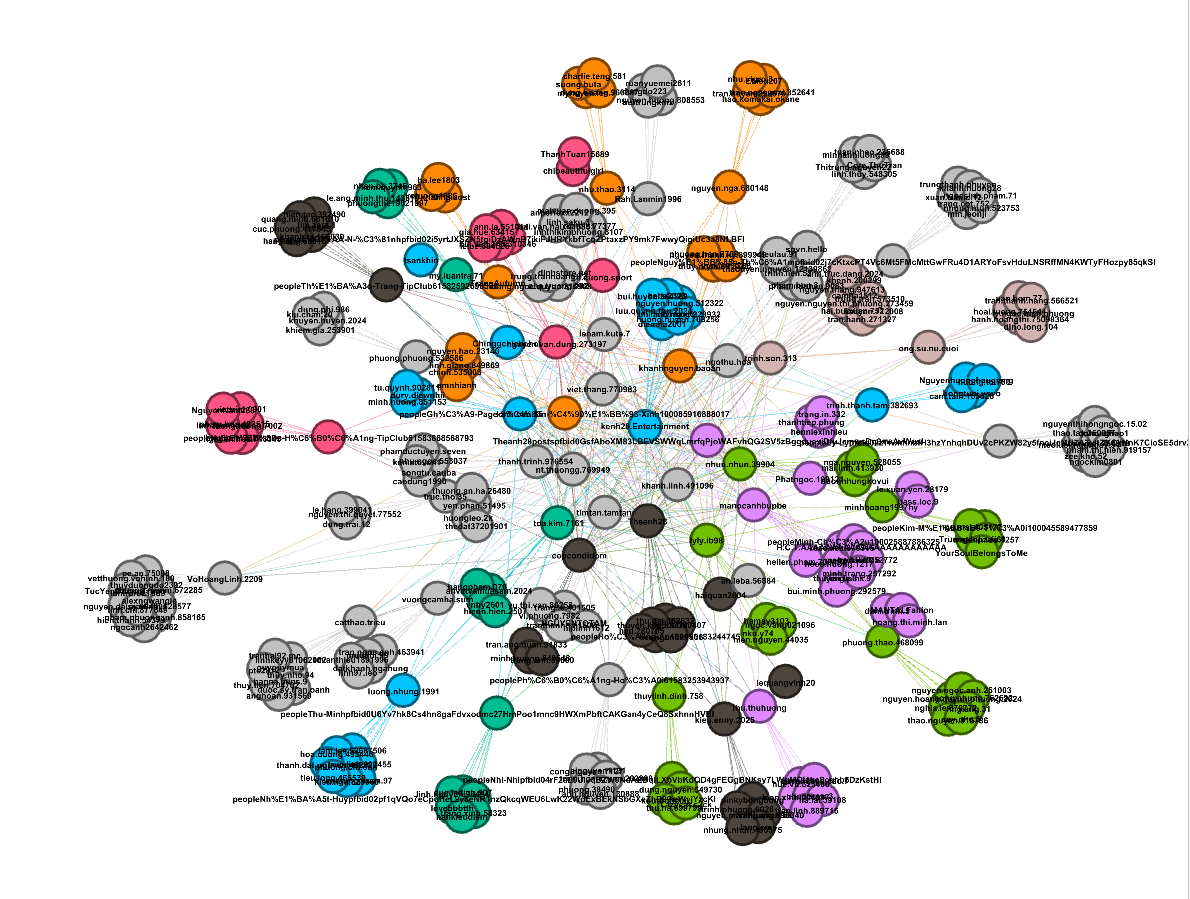

Hình ảnh từ Gephi

Đồ thị ForceAtlas2 mô tả cấu trúc cộng đồng của mạng lưới thảo luận Facebook gồm 301 người dùng, được tô màu theo thuật toán Louvain, cho thấy các cụm thảo luận tách biệt rõ rệt. Các nhóm màu như Cam, Xanh ngọc, Hồng hay Tím hình thành thành những “đảo” độc lập, phản ánh xu hướng tương tác nội bộ mạnh hơn giao tiếp với các nhóm khác. Một vài nút có kích thước lớn hơn—như nút Xanh dương ở trung tâm hoặc nút Cam phía trên—đại diện cho người dùng có PageRank cao, đóng vai trò như những nhân vật dẫn dắt hoặc trung tâm của từng cộng đồng. Từ các nút cốt lõi này, mạng lưới tỏa ra các nhánh vệ tinh nhỏ hơn, mô phỏng chính xác cấu trúc hội thoại trên Facebook, nơi các thảo luận phát triển thành nhiều chuỗi nhánh liên kết xoay quanh một số gương mặt nổi bật.